# Steps 1–2 · Sector landscape and competitive landscape · Underwater drones

**PW Innovation Management · Team 10 · client: Fincantieri** · notebook `03_landscape`

This notebook answers the questions of **Step 1 (general description of the sector)** and **Step 2 (competitive
landscape)** of the presentation deck. It reads only the clean tables written by `step_0_HL/02_clean.ipynb`
(`outputs/<env>/step1/`) and needs **no PATSTAT query** (two optional cells, switched off by default, run on TIP).

| Deck question (kick-off) | Section | Course link |
|---|---|---|
| How big is the field, is it growing, flat or declining? | 1.1 | Tutorial 0 nb 02 §7; IM_Theory_3 (shares control for the general growth of patenting) |
| Where is the field in its life cycle (trajectory)? | 1.2 | lecture on technological trajectories; IM_Theory_3 *Innovation Maturity Matrix* |
| Which technologies make up the field, how is the mix shifting? | 1.3 | Tutorial 0 nb 02 §8; IM_Theory_1 (IPC/CPC) |
| Where is it happening (markets vs R&D)? | 1.4 | Tutorial 0 nb 02 §9; Tutorial 1 nb 10 §7.2; IM_Theory_1 (rights are national, inventors show where R&D is done) |
| Patent-heavy or secrecy-reliant? How do firms protect inventions? | 1.5 | IM_Theory_0 (appropriability, informal methods), IM_Theory_1 (routes, opposition), IM_Theory_2 (choices 1–4, PE vs NPE, licensing) |
| How concentrated is the field, is it consolidating? | 2.1 | Tutorial 1 nb 11 §3–5.1 (Liston-Heyes & Pilkington, 2004) |
| Who are the incumbents and the new entrants? Which players to score? | 2.2–2.3 | Tutorial 1 nb 11 §5.2 |
| Which subfields are growing fastest? | 2.4 | Tutorial 1 nb 11 §5.3; Tutorial 2 nb 21 §9 (topics from text) |
| Who leads where, who works with whom? | 2.5–2.6 | Patel & Pavitt (1997) RTA; IM_Theory_2 (universities, collaboration) |
| Where does the client stand? | 2.7 | sets up Step 6 (Teece, 1986) |
| Which P, E, S, T forces shape it? | 2.8 | Tutorial 1 nb 11 §5.4 (mandatory PEST table) |

**Counting rules** (same as Step 0, to be stated once in the technical appendix): unit = DOCDB family; year = earliest
priority year of the family; years after `LAST_COMPLETE_YEAR` (2022) are incomplete (18-month publication lag),
shaded in grey and never read as a decline; applicants are the harmonised groups of `02_clean` (normalisation,
data-driven merge, verified corporate groups); fractional counting splits a family equally among its applicants /
countries / CPC subclasses.

**Robustness, everywhere.** Step 0 left two open issues: block 6 has a precision of 48%, and about 80% of the
families are first filed in China, where patent subsidies inflate counts (Dang & Motohashi, 2015). Every headline
number is therefore computed on three samples: **all** families, **without block-6-only** families, and
**international** families only (filed at more than one office or via PCT: the WIPO (2024) choice discussed in
IM_Theory_3, "to control for value and national biases").

## 0 · Setup

In [1]:
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats
from scipy.optimize import curve_fit

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------------------------------------------------------------- where the Step 0 folder is

import config as C  

IN = Path("outputs") / C.ENV.lower() / "step1"             # legge direttamente da outputs/<env>/step1
OUT = Path("outputs") / C.ENV.lower() / "step2"            # scrive in outputs/<env>/step2
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
# ---------------------------------------------------------------- analysis settings (design choices: justify them)
LAST = C.LAST_COMPLETE_YEAR                # 2022: last complete priority year
YEAR_MIN, YEAR_MAX = C.YEAR_MIN, C.YEAR_MAX
SPLIT_YEAR = 2015                          # incumbents: first family in the sector before 2015; entrants: from 2015
WINDOW = 3                                 # years per window when following concentration over time
PAST = (LAST - 9, LAST - 5)                # 2013-2017
RECENT = (LAST - 4, LAST)                  # 2018-2022
TOP_N = 15
MIN_FAMILIES_SCORE = 10                    # gate for the Step 3 shortlist (Clarivate-style volume gate, Tutorial 4)
CLIENT = "FINCANTIERI"
RUN_PATSTAT = False                        # True only on TIP: optional cells that query PATSTAT

NAVY, ORANGE, BLUE, GREY, MID, LIGHT, GREEN, RED = ("#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB",
                                                    "#D9E1E8", "#7A9A3A", "#A23B72")
PALETTE = [NAVY, ORANGE, BLUE, GREEN, RED, MID, "#C9A227", "#5B8E7D", "#B5651D", "#6C5B7B"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "figure.dpi": 100, "savefig.dpi": 150, "axes.prop_cycle": plt.cycler(color=PALETTE)})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
print(f"{C.SECTOR_NAME} · env {C.ENV} · reading {IN} · writing {OUT} · complete years up to {LAST}")

Underwater drones · env PROD · reading outputs/prod/step1 · writing outputs/prod/step2 · complete years up to 2022


In [2]:
def shade(ax, last=LAST, right=YEAR_MAX):
    """Grey band on the incomplete (truncated) years."""
    ax.axvspan(last + 0.5, right + 0.5, color="grey", alpha=0.15, lw=0, label="incomplete years")

def save(fig, name):
    """Save a figure for the deck / appendix (png in outputs/<env>/step2/figures)."""
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

def cagr(first, last, years):
    return (last / first) ** (1 / years) - 1 if first > 0 and years > 0 else np.nan

def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

def short(df, n=45):
    """Shorter index labels for display (some PATSTAT names are 200 characters long)."""
    return df.rename(index=lambda s: s if not isinstance(s, str) or len(s) <= n else s[:n - 1] + "…")

KEY = {}     # headline numbers, saved at the end in key_numbers.json (every number of the deck traceable to here)

### 0.1 Data

All tables come from `02_clean`. `applicants.csv` already carries the harmonised group name (`applicant`), the type
and the country of each applicant of each family, and the fractional weights (each family sums to 1).
The **type of an applicant** is taken from `applicants_profile.csv` (one type per group), because `psn_sector`
can differ between the spellings of the same group (e.g. CSSC appears as *firm* and as *unknown*).

In [3]:
fam = pd.read_csv(IN / "families.csv", low_memory=False)
apps = pd.read_csv(IN / "applications.csv", low_memory=False)
appl = pd.read_csv(IN / "applicants.csv", low_memory=False)
prof = pd.read_csv(IN / "applicants_profile.csv", low_memory=False)
inv = pd.read_csv(IN / "inventors.csv", low_memory=False)
fcpc = pd.read_csv(IN / "family_cpc.csv", low_memory=False)
fsub = pd.read_csv(IN / "family_subclass.csv", low_memory=False)
fwipo = pd.read_csv(IN / "family_wipo_fields.csv", low_memory=False)
fwd = pd.read_csv(IN / "citations_forward.csv", low_memory=False)
bench_f = pd.read_csv(IN / "benchmark_families_per_year.csv")
bench_a = pd.read_csv(IN / "benchmark_applications_per_year.csv")
legal = pd.read_csv(IN / "legal_events.csv.gz", low_memory=False,
                    usecols=["docdb_family_id", "event_auth", "event_code", "event_descr", "ev_opposition", "ev_licence",
                             "ev_transfer", "ev_litigation", "ev_revocation", "ev_lapse", "ev_renewal_fee"])

# one type per applicant group (profile), and the client flag
appl["type"] = appl["applicant"].map(prof.set_index("applicant")["type"]).fillna(appl["applicant_type"])
appl["year"] = appl["family_year"]
for col in ["is_truncated", "granted_any", "via_pct", "is_international", "has_ep", "active_proxy",
            "fwd_window_complete", "has_en_abstract"]:
    fam[col] = fam[col].astype(str).str.lower().eq("true")

# ---------------------------------------------------------------- the three samples of every headline number
fam["b6_only"] = fam["block_combo"].eq("b6")
SAMPLES = {
    "all": fam["docdb_family_id"],
    "without block-6-only": fam.loc[~fam["b6_only"], "docdb_family_id"],
    "international": fam.loc[fam["is_international"], "docdb_family_id"],
}
SAMPLES = {k: set(v) for k, v in SAMPLES.items()}

print(f"{len(fam):,} families, {len(apps):,} applications, {appl['applicant'].nunique():,} applicant groups, "
      f"{len(fcpc):,} family-CPC rows")
pd.DataFrame({"families": {k: len(v) for k, v in SAMPLES.items()},
              "share of all": {k: pct(len(v) / len(fam)) for k, v in SAMPLES.items()}})

15,755 families, 20,430 applications, 5,175 applicant groups, 58,717 family-CPC rows


,families,share of all
all,15755,100.0%
without block-6-only,11968,76.0%
international,1329,8.4%


# STEP 1 · General description of the sector

## 1.1 Volume: how big is the sector, and is it growing?

Families per priority year (the PW unit) next to applications per filing year (how much protection is sought).
The gap between the two is the average number of applications per invention. Growth is compared with **all
patents** and with the neighbouring field **B63 (ships and marine technology)**: a sector that grows is special only
if it grows faster than patenting as a whole (IM_Theory_3: *"why shares: they control for the general growth of
patent filings"*).

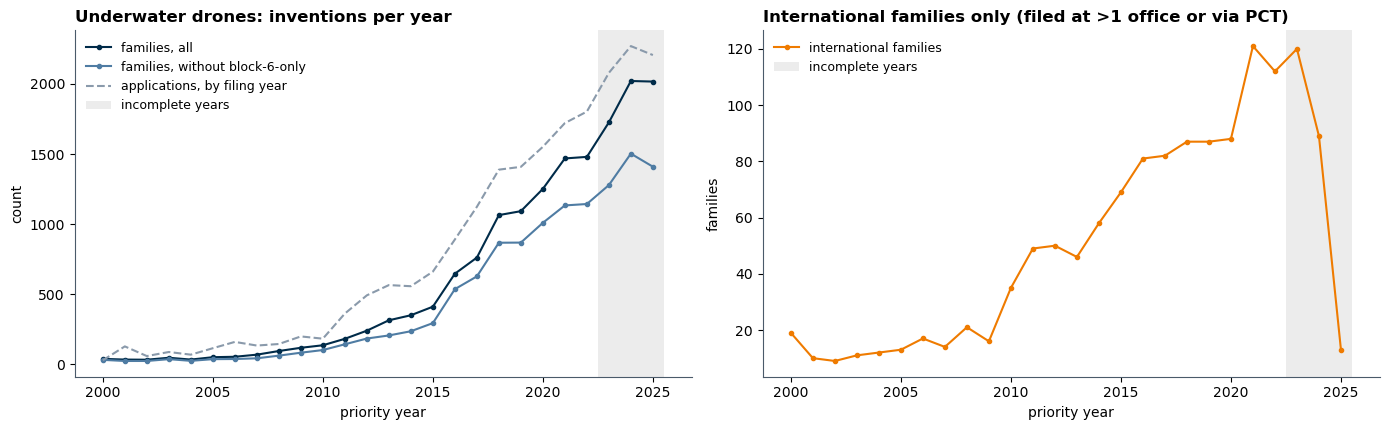

,2000,2005,2010,2015,2018,2020,2021,2022,2023,2024,2025
families · all,40,52,137,412,1065,1252,1469,1480,1726,2021,2017
families · without block-6-only,33,38,103,295,868,1010,1134,1144,1279,1503,1410
families · international,19,13,35,69,87,88,121,112,120,89,13
applications (filing year),30,116,184,662,1389,1552,1721,1803,2079,2270,2206


In [4]:
years = np.arange(YEAR_MIN, YEAR_MAX + 1)
vol = pd.DataFrame(index=years)
for name, ids in SAMPLES.items():
    vol[f"families · {name}"] = fam[fam["docdb_family_id"].isin(ids)].groupby("family_year").size()
vol["applications (filing year)"] = apps[apps["in_appln_window"]].groupby("appln_filing_year").size()
vol = vol.fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
ax.plot(vol.index, vol["families · all"], marker="o", ms=3, color=NAVY, label="families, all")
ax.plot(vol.index, vol["families · without block-6-only"], marker="o", ms=3, color=BLUE, label="families, without block-6-only")
ax.plot(vol.index, vol["applications (filing year)"], ls="--", color=MID, label="applications, by filing year")
shade(ax); ax.legend(frameon=False, fontsize=9); ax.set(title="Underwater drones: inventions per year", xlabel="priority year", ylabel="count")
ax = axes[1]
ax.plot(vol.index, vol["families · international"], marker="o", ms=3, color=ORANGE, label="international families")
shade(ax); ax.legend(frameon=False, fontsize=9)
ax.set(title="International families only (filed at >1 office or via PCT)", xlabel="priority year", ylabel="families")
plt.tight_layout(); save(fig, "s1_volume"); plt.show()
vol.loc[[2000, 2005, 2010, 2015, 2018, 2020, 2021, 2022, 2023, 2024, 2025]].T

**Growth versus patenting overall.** Compound annual growth rate (CAGR) on complete years only, in two windows:
the whole period (2000–2022) and the last decade (2012–2022). The index chart puts the three series at 100 in 2012.

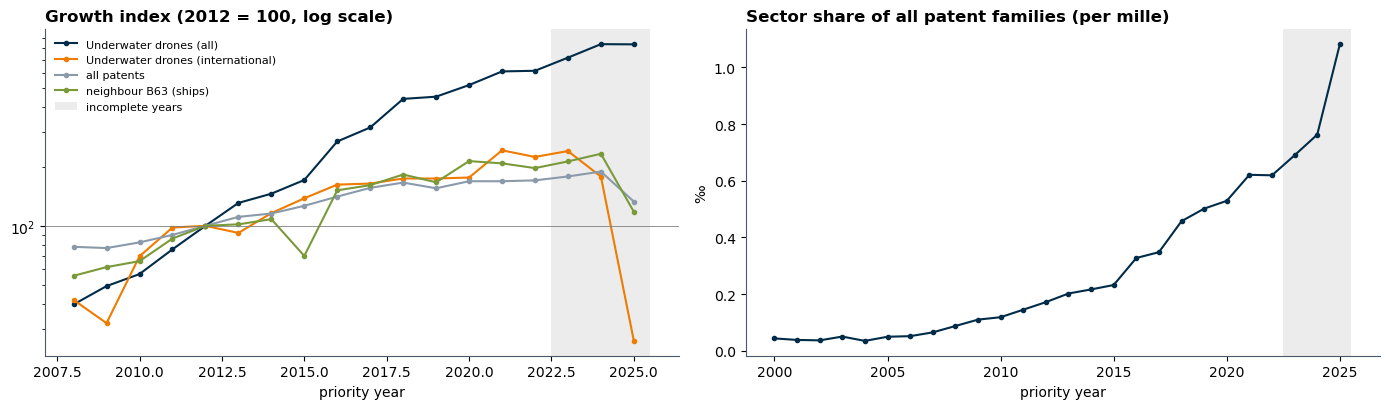

,families 2012,families 2022,CAGR 2000-2022,CAGR 2012-2022
Underwater drones (all),241,"1,480",17.8%,19.9%
Underwater drones (without b6-only),185,"1,144",17.5%,20.0%
Underwater drones (international),50,112,8.4%,8.4%
all patents,"1,403,316","2,389,326",4.5%,5.5%
neighbour B63 (ships),"5,074","9,973",8.2%,7.0%


In [5]:
b = bench_f.set_index("year")
series = {"Underwater drones (all)": vol["families · all"], "Underwater drones (without b6-only)": vol["families · without block-6-only"],
          "Underwater drones (international)": vol["families · international"],
          "all patents": b["all patents"], "neighbour B63 (ships)": b["neighbour B63"]}
rows = {}
for name, s in series.items():
    rows[name] = {"families 2012": s.loc[2012], f"families {LAST}": s.loc[LAST],
                  f"CAGR 2000-{LAST}": cagr(s.loc[2000], s.loc[LAST], LAST - 2000),
                  f"CAGR 2012-{LAST}": cagr(s.loc[2012], s.loc[LAST], LAST - 2012)}
growth = pd.DataFrame(rows).T
KEY["families_total"] = int(len(fam)); KEY["families_complete_years"] = int((fam.family_year <= LAST).sum())
KEY["cagr_2012_last_sector"] = float(growth.loc["Underwater drones (all)", f"CAGR 2012-{LAST}"])
KEY["cagr_2012_last_all_patents"] = float(growth.loc["all patents", f"CAGR 2012-{LAST}"])
KEY["cagr_2012_last_B63"] = float(growth.loc["neighbour B63 (ships)", f"CAGR 2012-{LAST}"])

idx = pd.DataFrame({k: v.loc[2008:YEAR_MAX] / v.loc[2012] * 100 for k, v in series.items() if "b6" not in k})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for k, c in zip(idx.columns, [NAVY, ORANGE, MID, GREEN]):
    axes[0].plot(idx.index, idx[k], marker="o", ms=3, color=c, label=k)
shade(axes[0]); axes[0].set_yscale("log"); axes[0].axhline(100, color="grey", lw=0.6)
axes[0].set(title="Growth index (2012 = 100, log scale)", xlabel="priority year"); axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(b.index, b["sector share of all (per mille)"], marker="o", ms=3, color=NAVY)
shade(axes[1]); axes[1].set(title="Sector share of all patent families (per mille)", xlabel="priority year", ylabel="‰")
plt.tight_layout(); save(fig, "s1_growth_vs_benchmarks"); plt.show()
growth.style.format({c: "{:.1%}" for c in growth.columns if "CAGR" in c} | {c: "{:,.0f}" for c in growth.columns if "families" in c})

**Reading.** The sector grows much faster than patenting overall and than its neighbouring field: its share of all
families rises year after year, so underwater drones are *gaining weight* in technology, not just riding the general
boom of (Chinese) patenting. The international series grows far less: most of the boom is domestic Chinese filing
(Section 1.4). Report both series side by side in the deck.

## 1.2 Life cycle: where is the sector on its technological trajectory?

Technologies typically follow an **S-curve**: slow emergence, fast growth, then saturation as a dominant design
emerges and effort moves from product to process innovation (Utterback & Abernathy, 1975; lecture on
technological trajectories). Two complementary measures:

1. a **logistic fit** of the cumulative number of families, $N(t)=K/(1+e^{-r(t-t_0)})$: $t_0$ is the inflection year
   (fastest growth), $K$ the saturation level. Fitted on complete years only; a fit whose inflection lies beyond the
   data means *no inflection observed yet* (the sector is still in the growth phase), and $K$ is then not reliable;
2. the **Innovation Maturity Matrix** of the WIPO (2024) SDG report (IM_Theory_3): for each subfield, its
   *intensity* (number of families) and its *relative recency*
   $R=\sum_i w_i\, i/(n\sum_i w_i)$ ($i$ = year index, $w_i$ = families of year $i$), divided by the $R$ of the whole
   sector. Many and recent = *current hot topics*; few and recent = *emerging*; older = *mature*.

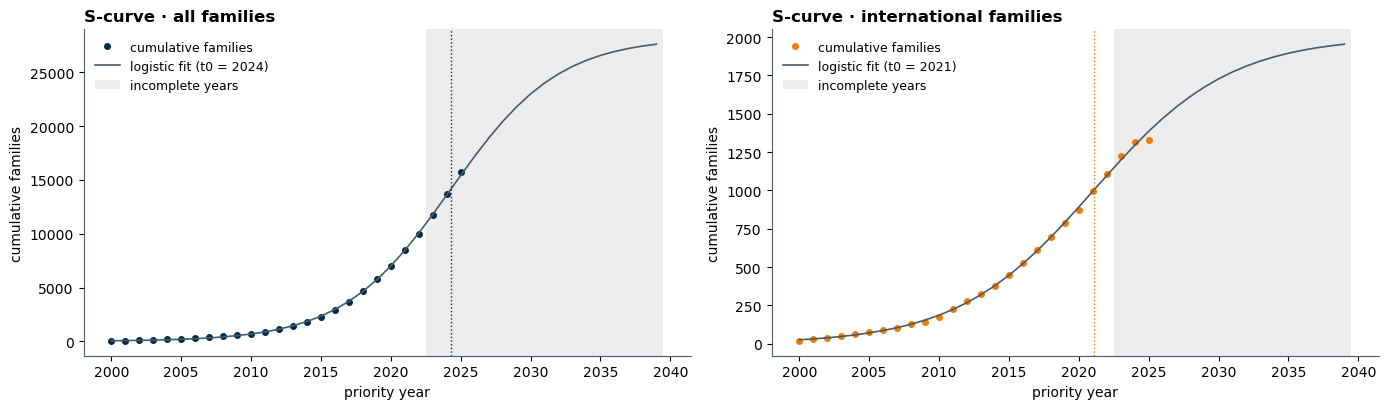

,"K (saturation, families)",r (growth rate),t0 (inflection year),R2,share of K reached,inflection observed
all,"28,234",0.26,2024.3,1.000,35%,False
without block-6-only,"19,642",0.28,2023.5,0.999,40%,False
international,"2,003",0.21,2021.1,1.000,55%,True
"all, including 2023-2025 (lower bound)","31,124",0.25,2024.9,1.000,51%,True


In [6]:
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

def fit_s_curve(yearly, last=LAST):
    s = yearly.loc[:last].cumsum()
    t = s.index.values.astype(float); y = s.values.astype(float)
    p0 = [y[-1] * 2, 0.3, t[-1]]
    bounds = ([y[-1], 0.01, t[0]], [y[-1] * 50, 2.0, t[-1] + 30])
    p, _ = curve_fit(logistic, t, y, p0=p0, bounds=bounds, maxfev=20000)
    r2 = 1 - np.sum((y - logistic(t, *p)) ** 2) / np.sum((y - y.mean()) ** 2)
    return {"K (saturation, families)": p[0], "r (growth rate)": p[1], "t0 (inflection year)": p[2], "R2": r2,
            "share of K reached": y[-1] / p[0], "inflection observed": p[2] <= last}

life = {}
for name in SAMPLES:
    life[name] = fit_s_curve(vol[f"families · {name}"])
life["all, including 2023-2025 (lower bound)"] = fit_s_curve(vol["families · all"], last=YEAR_MAX)
life = pd.DataFrame(life).T
KEY["s_curve_t0_all"] = float(life.loc["all", "t0 (inflection year)"])
KEY["s_curve_t0_international"] = float(life.loc["international", "t0 (inflection year)"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, name, c in zip(axes, ["all", "international"], [NAVY, ORANGE]):
    s = vol[f"families · {name}"].cumsum()
    p = life.loc[name, ["K (saturation, families)", "r (growth rate)", "t0 (inflection year)"]].astype(float).values
    tt = np.arange(YEAR_MIN, YEAR_MAX + 15)
    ax.plot(s.index, s.values, "o", ms=4, color=c, label="cumulative families")
    ax.plot(tt, logistic(tt, *p), color=GREY, lw=1.2, label=f"logistic fit (t0 = {p[2]:.0f})")
    ax.axvline(p[2], color=c, ls=":", lw=1)
    shade(ax, right=YEAR_MAX + 14); ax.set(title=f"S-curve · {name} families", xlabel="priority year", ylabel="cumulative families")
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save(fig, "s1_s_curve"); plt.show()
life.style.format({"K (saturation, families)": "{:,.0f}", "r (growth rate)": "{:.2f}", "t0 (inflection year)": "{:.1f}",
                   "R2": "{:.3f}", "share of K reached": "{:.0%}"})

**Reading and caveat.** Read $t_0$ and the share of $K$ reached, not $K$ itself: extrapolating a logistic from a
curve that has not bent yet is fragile (Ernst, 1997, warns that patent S-curves identify the *phase*, not the
final size). If the international curve bends earlier than the domestic one, the *quality* frontier of the sector is
maturing while the volume keeps growing.

**A process-innovation proxy.** In the Utterback–Abernathy model, the mature phase shifts effort from *product* to
*process* innovation. A cheap proxy is the share of families whose English title describes a *method / process*
rather than a device. It is only a proxy (Chinese titles often read "...method and system"), so read the trend, not
the level.

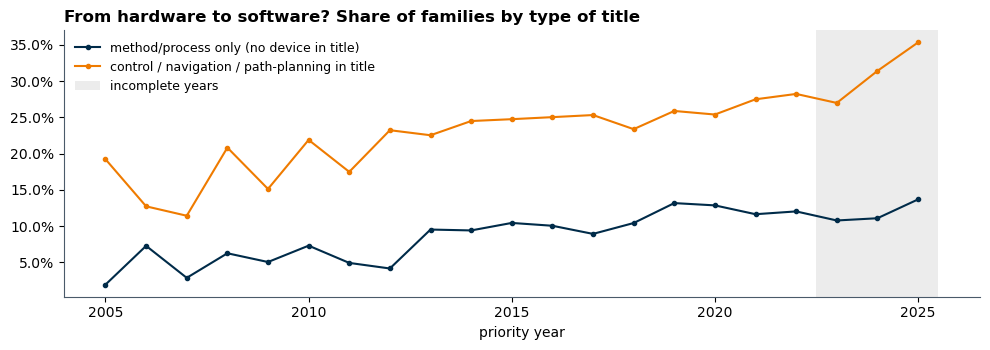

,is_method_title,is_control_title
family_year,,
2005,0.019,0.192
2010,0.073,0.219
2015,0.104,0.248
2018,0.104,0.234
2020,0.129,0.254
2022,0.120,0.282


In [7]:
title = fam["title_en"].fillna(fam["title"]).fillna("").str.lower()
fam["is_method_title"] = title.str.contains(r"\bmethod\b|\bprocess\b") & ~title.str.contains(r"\b(?:device|apparatus|vehicle|robot|system)\b")
fam["is_control_title"] = title.str.contains(r"control|navigat|path|planning|positioning|tracking|localization|formation")
proc = fam[fam.family_year.between(2005, YEAR_MAX)].groupby("family_year")[["is_method_title", "is_control_title"]].mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(proc.index, proc["is_method_title"] * 100, marker="o", ms=3, color=NAVY, label="method/process only (no device in title)")
ax.plot(proc.index, proc["is_control_title"] * 100, marker="o", ms=3, color=ORANGE, label="control / navigation / path-planning in title")
shade(ax); ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.legend(frameon=False, fontsize=9)
ax.set(title="From hardware to software? Share of families by type of title", xlabel="priority year")
plt.tight_layout(); save(fig, "s1_process_proxy"); plt.show()
proc.loc[[2005, 2010, 2015, 2018, 2020, 2022]].round(3)

## 1.3 Technology mix: which technologies make up the field, and how is the mix shifting?

### 1.3.1 CPC subclasses (fractional counting)

Each family is split equally across its CPC subclasses (`family_subclass.csv`), so the shares sum to 100%.
Many subclasses are co-classifications: they show which neighbouring technologies the sector draws on (navigation,
control, AI, sonar...). **The official titles below must be checked on the CPC scheme before they go in the deck**
(https://www.cooperativepatentclassification.org): they are short versions.

In [8]:
CPC_TITLES = {   # short titles: VERIFY against the official CPC scheme before using them in the deck
    "B63G": "Offensive/defensive arrangements on vessels; submarines (incl. unmanned underwater vessels)",
    "B63C": "Launching/docking vessels; life-saving; equipment for working under water; searching for underwater objects",
    "G05D": "Control of non-electric variables (incl. position/course of vehicles, G05D 1)",
    "B63B": "Ships or other waterborne vessels; equipment for shipping",
    "G01C": "Measuring distances, levels or bearings; surveying; navigation",
    "B63H": "Marine propulsion or steering",
    "G01S": "Radio/acoustic direction-finding, navigation, ranging and locating (incl. sonar)",
    "G05B": "Control or regulating systems in general",
    "B25J": "Manipulators; robots",
    "Y02A": "Technologies for adaptation to climate change (tagging)",
    "G06F": "Electric digital data processing",
    "Y02T": "Climate change mitigation technologies related to transportation (tagging)",
    "G06N": "Computing arrangements based on specific computational models (AI, neural networks)",
    "G01N": "Investigating or analysing materials (chemical or physical properties)",
    "G06T": "Image data processing or generation",
    "Y02E": "GHG emission reduction in energy generation, transmission, distribution (tagging)",
    "G01V": "Geophysics; detecting masses or objects",
    "G06V": "Image or video recognition or understanding",
    "H04B": "Transmission (incl. underwater acoustic communication)",
    "G01M": "Testing of machines or structures",
    "H02J": "Supplying or distributing electric power; energy storage systems",
    "E21B": "Earth or rock drilling; obtaining oil, gas or water from wells",
    "B08B": "Cleaning in general",
    "H04N": "Pictorial communication (cameras, video)",
    "Y02P": "Climate change mitigation in the production of goods (tagging)",
    "H01M": "Batteries and fuel cells", "B60L": "Electric propulsion of vehicles",
    "F16L": "Pipes and pipe-line systems", "B64U": "Unmanned aerial vehicles", "A01K": "Animal husbandry; fishing",
    "G08G": "Traffic control systems", "H04W": "Wireless communication networks", "G06Q": "Business methods",
    "E02F": "Dredging; soil shifting", "B66C": "Cranes", "G01D": "Measuring not specially adapted to a variable",
}
sub = fsub.merge(fam[["docdb_family_id", "family_year", "is_international", "b6_only"]], on="docdb_family_id")
sub_c = sub[sub["family_year"] <= LAST]

def share_by(df, key, weight="weight", top=12):
    s = df.groupby(key)[weight].sum().sort_values(ascending=False)
    s = s / s.sum()
    out = s.head(top); out.loc["Other"] = s.iloc[top:].sum()
    return out

mix = pd.DataFrame({"all": share_by(sub_c, "subclass"),
                    "without b6-only": share_by(sub_c[~sub_c.b6_only], "subclass").reindex(share_by(sub_c, "subclass").index),
                    "international": share_by(sub_c[sub_c.is_international], "subclass").reindex(share_by(sub_c, "subclass").index)})
mix["CPC title (verify)"] = [CPC_TITLES.get(i, "") for i in mix.index]
mix.style.format({c: "{:.1%}" for c in ["all", "without b6-only", "international"]}, na_rep="–")

,all,without b6-only,international,CPC title (verify)
subclass,,,,
B63G,16.1%,18.6%,24.8%,Offensive/defensive arrangements on vessels; submarines (incl. unmanned underwater vessels)
B63C,14.1%,16.7%,9.2%,Launching/docking vessels; life-saving; equipment for working under water; searching for underwater objects
G05D,7.6%,7.6%,3.7%,"Control of non-electric variables (incl. position/course of vehicles, G05D 1)"
B63B,6.4%,6.6%,11.2%,Ships or other waterborne vessels; equipment for shipping
B63H,4.1%,4.7%,3.3%,Marine propulsion or steering
G01S,4.1%,3.4%,3.7%,"Radio/acoustic direction-finding, navigation, ranging and locating (incl. sonar)"
G01C,3.7%,3.0%,1.7%,"Measuring distances, levels or bearings; surveying; navigation"
B25J,3.5%,3.6%,2.1%,Manipulators; robots
G05B,2.6%,2.7%,–,Control or regulating systems in general


**How is the mix shifting?** Share of each subclass per year (stacked to 100%), and the change in share between the
past window (2013–2017) and the recent one (2018–2022), in percentage points. Rising shares of G05D/G06N/G06F/G06V
would mean that the frontier moves from the vehicle (hull, propulsion: B63) to its *brain* (control, AI, vision).

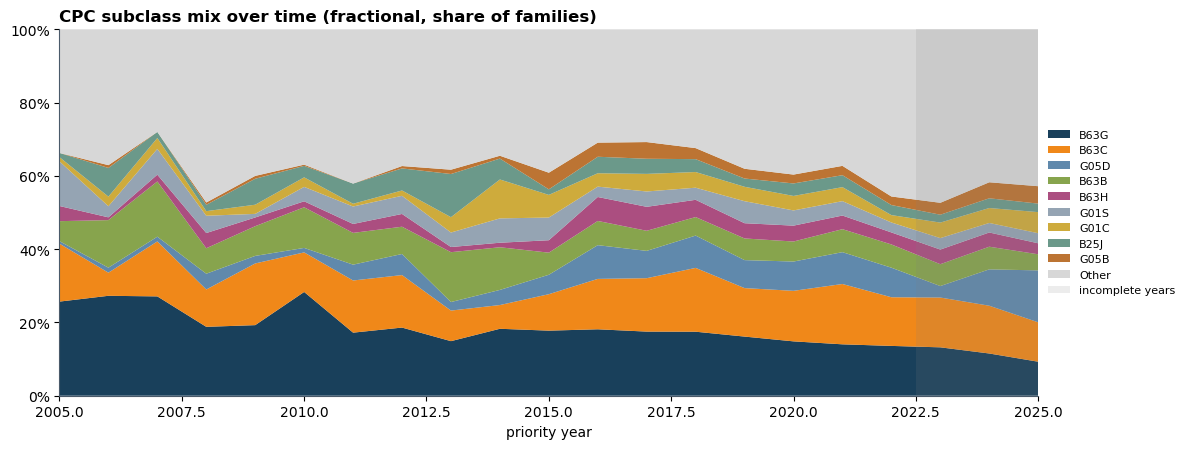

,share 2013-2017,share 2018-2022,change (pp)
subclass,,,
B63G,17.6%,15.0%,-2.5
B25J,4.8%,3.1%,-1.7
G01C,5.1%,3.5%,-1.6
B63B,7.3%,5.9%,-1.4
B63H,5.1%,4.0%,-1.1
G05B,3.6%,2.6%,-1.1
G06N,0.3%,1.1%,+0.9
G06F,1.2%,2.4%,+1.2
G05D,6.9%,8.3%,+1.3


In [9]:
top_sub = share_by(sub_c, "subclass", top=9).index.drop("Other")
yearly_mix = (sub[sub.family_year.between(2005, YEAR_MAX)]
              .assign(subclass=lambda d: d["subclass"].where(d["subclass"].isin(top_sub), "Other"))
              .pivot_table(index="family_year", columns="subclass", values="weight", aggfunc="sum", fill_value=0))
yearly_mix = yearly_mix.div(yearly_mix.sum(axis=1), axis=0)[list(top_sub) + ["Other"]] * 100

fig, ax = plt.subplots(figsize=(12, 4.6))
cols = PALETTE[:len(top_sub)] + ["lightgrey"]
ax.stackplot(yearly_mix.index, yearly_mix.T.values, labels=yearly_mix.columns, colors=cols, alpha=0.9)
shade(ax); ax.set(title="CPC subclass mix over time (fractional, share of families)", xlabel="priority year", ylim=(0, 100), xlim=(2005, YEAR_MAX))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8, frameon=False)
plt.tight_layout(); save(fig, "s1_cpc_mix_over_time"); plt.show()

def window_share(df, key, period, weight="weight"):
    d = df[df.family_year.between(*period)]
    s = d.groupby(key)[weight].sum()
    return s / s.sum()

shift = pd.DataFrame({f"share {PAST[0]}-{PAST[1]}": window_share(sub, "subclass", PAST),
                      f"share {RECENT[0]}-{RECENT[1]}": window_share(sub, "subclass", RECENT)}).fillna(0)
shift["change (pp)"] = (shift.iloc[:, 1] - shift.iloc[:, 0]) * 100
shift = shift[shift.iloc[:, 1] >= 0.005].sort_values("change (pp)")
pd.concat([shift.head(6), shift.tail(6)]).style.format({shift.columns[0]: "{:.1%}", shift.columns[1]: "{:.1%}", "change (pp)": "{:+.1f}"})

### 1.3.2 WIPO technology sectors and fields (Schmoch, 2008)

A coarser view, comparable across sectors and countries: of 100 families, how many are in each of the 5 WIPO
technology sectors, and how does it change over time?

In [10]:
w = fwipo.merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id")
w_c = w[w.family_year <= LAST]
wsec = pd.DataFrame({"all years": share_by(w_c, "techn_sector", top=5).drop("Other"),
                     f"{PAST[0]}-{PAST[1]}": window_share(w, "techn_sector", PAST),
                     f"{RECENT[0]}-{RECENT[1]}": window_share(w, "techn_sector", RECENT)})
wfield = pd.DataFrame({"all years": share_by(w_c, "techn_field", top=10),
                       f"{PAST[0]}-{PAST[1]}": window_share(w, "techn_field", PAST),
                       f"{RECENT[0]}-{RECENT[1]}": window_share(w, "techn_field", RECENT)}).loc[lambda d: d.index != "Other"]
display(wsec.style.format("{:.1%}"))
wfield.sort_values("all years", ascending=False).style.format("{:.1%}", na_rep="–")

,all years,2013-2017,2018-2022
techn_sector,,,
Chemistry,1.6%,1.4%,1.6%
Electrical engineering,13.5%,10.8%,15.2%
Instruments,27.2%,27.9%,27.4%
Mechanical engineering,54.7%,56.8%,53.2%
Other fields,3.1%,3.1%,2.6%


,all years,2013-2017,2018-2022
techn_field,,,
Transport,43.9%,44.6%,43.6%
Measurement,14.5%,14.7%,14.1%
Control,11.8%,12.5%,12.5%
Handling,5.7%,6.7%,5.1%
Computer technology,5.3%,3.3%,6.7%
"Electrical machinery, apparatus, energy",3.9%,3.5%,4.0%
Civil engineering,2.8%,2.7%,2.4%
Mechanical elements,2.0%,2.1%,1.9%
Telecommunications,1.7%,1.7%,1.7%


### 1.3.3 Recombination: are inventions combining more technologies?

The number of distinct CPC subclasses per family is a simple measure of how many technologies an invention
combines (a bridge to the lecture *Innovation as recombination*, 14 Dec, and to the novel-recombination ingredient of
the Step 4 future score). A rising trend means the field becomes more systemic (vehicle + sensing + software).

In [11]:
rec = fam[fam.family_year.between(2005, LAST)].groupby("family_year")["n_subclasses"].agg(["mean", "median"])
rec["share with ≥3 subclasses"] = fam[fam.family_year.between(2005, LAST)].groupby("family_year")["n_subclasses"].apply(lambda s: (s >= 3).mean())
rec.loc[[2005, 2010, 2015, 2018, 2020, 2022]].round(2)

,mean,median,share with ≥3 subclasses
family_year,,,
2005,2.17,2.0,0.23
2010,2.44,2.0,0.18
2015,2.05,2.0,0.16
2018,1.86,2.0,0.18
2020,2.15,2.0,0.30
2022,2.17,2.0,0.28


## 1.4 Geography: where is protection sought, who owns the technology, where is the R&D done?

Three different questions, three different fields (IM_Theory_1 and IM_Theory_3, *who / where*):

| Question | Field | Note |
|---|---|---|
| Where is the invention first filed (origin)? | `first_office` (priority office) | home market of the applicant |
| Where is protection sought (markets)? | offices of the family (`offices`) | *"the countries in the family are the courts where the owner will be able to sue"* (IM_Theory_2) |
| Who owns it? | applicant country (fractional) | headquarters, sometimes a holding |
| Where is the R&D done? | inventor country (fractional) | *"inventor addresses show where the research is actually done"* (IM_Theory_1) |

Missing countries: `02_clean` falls back on the national filing office when the person's country is missing
(Tutorial 1 nb 10 §7.2: otherwise China and Japan disappear). `country_source` says which.

In [12]:
fam_c = fam[fam.family_year <= LAST]
origin = fam_c["first_office"].value_counts(normalize=True).head(10)
offices = fam_c["offices"].str.split().explode()
markets = (offices.value_counts() / len(fam_c)).head(12)

app_ctry = appl[appl.family_year <= LAST].groupby("country")["country_weight"].sum()
inv_ctry = inv.merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id").query("family_year <= @LAST").groupby("country")["country_weight"].sum()
geo = pd.DataFrame({"applicant share (owners)": app_ctry / app_ctry.sum(), "inventor share (R&D)": inv_ctry / inv_ctry.sum()}).fillna(0)
geo["gap (pp, inventors − owners)"] = (geo.iloc[:, 1] - geo.iloc[:, 0]) * 100
geo = geo.sort_values("applicant share (owners)", ascending=False).head(14)
KEY["share_first_filed_CN"] = float((fam_c.first_office == "CN").mean())
KEY["share_international"] = float(fam_c.is_international.mean())

display(pd.DataFrame({"first filing office (share of families)": origin}).style.format("{:.1%}"))
display(pd.DataFrame({"families with an application at the office": markets}).style.format("{:.1%}"))
geo.style.format({"applicant share (owners)": "{:.1%}", "inventor share (R&D)": "{:.1%}", "gap (pp, inventors − owners)": "{:+.2f}"})

,first filing office (share of families)
first_office,
CN,73.1%
KR,7.3%
US,6.0%
WO,2.8%
RU,2.4%
JP,1.8%
GB,1.4%
DE,1.1%
FR,0.8%


,families with an application at the office
offices,
CN,74.5%
US,12.1%
WO,9.6%
KR,7.9%
EP,5.7%
JP,3.2%
AU,2.8%
RU,2.7%
GB,2.0%


,applicant share (owners),inventor share (R&D),"gap (pp, inventors − owners)"
country,,,
CN,74.1%,74.2%,+0.12
KR,7.3%,7.4%,+0.11
US,6.2%,5.9%,-0.27
RU,2.4%,2.5%,+0.07
JP,2.1%,2.1%,+0.01
GB,1.3%,1.1%,-0.25
DE,1.2%,1.1%,-0.11
FR,1.2%,1.1%,-0.02
NO,1.1%,1.1%,-0.02


**Origin over time.** The share of China among first filings, and the internationalisation rate by origin.
Internationalisation is the cleanest *value* signal available for every family: filing abroad is costly (fees,
translations, attorneys multiplied by every country, IM_Theory_1), so applicants do it only for inventions they
expect to be worth it. A low international share for Chinese families is consistent with subsidy-driven domestic
filing (Dang & Motohashi, 2015) and with university portfolios that "stop at the national filing" (IM_Theory_2).

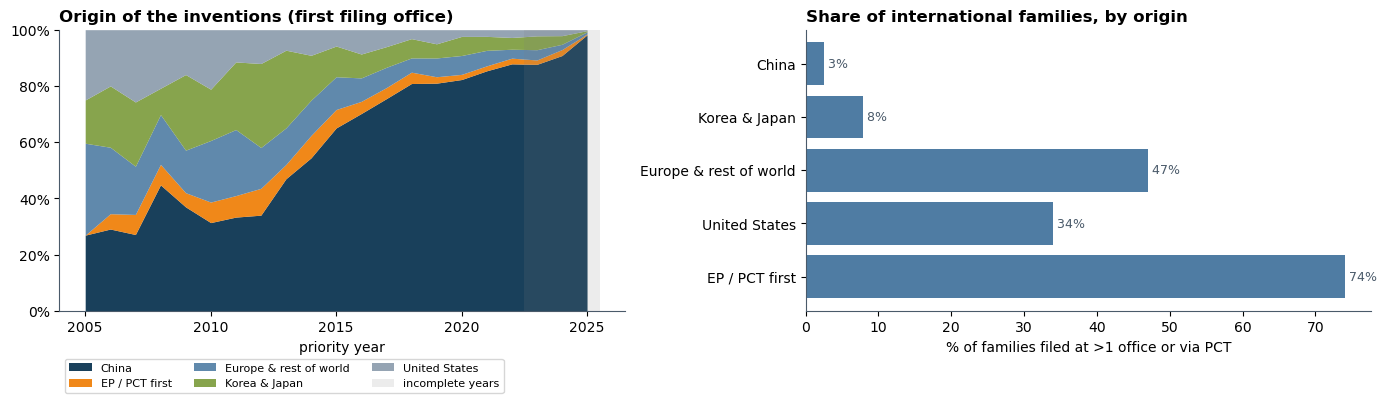

,families,international,mean_offices,granted
origin_group,,,,
China,7304,2.5%,1.03,61.3%
Korea & Japan,904,7.9%,1.19,75.4%
Europe & rest of world,841,47.0%,2.74,82.5%
United States,596,33.9%,1.97,80.5%
EP / PCT first,346,74.0%,3.33,60.4%


In [13]:
fam["origin_group"] = np.where(fam.first_office.eq("CN"), "China", np.where(fam.first_office.isin(["US"]), "United States",
                       np.where(fam.first_office.isin(["KR", "JP"]), "Korea & Japan",
                       np.where(fam.first_office.isin(["EP", "WO"]), "EP / PCT first", "Europe & rest of world"))))
fam_c = fam[fam.family_year <= LAST]
og = fam[fam.family_year.between(2005, YEAR_MAX)].groupby(["family_year", "origin_group"]).size().unstack(fill_value=0)
og_share = og.div(og.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
og_share.plot.area(ax=axes[0], color=[NAVY, ORANGE, BLUE, GREEN, MID][:og_share.shape[1]], alpha=0.9, lw=0)
shade(axes[0]); axes[0].set(title="Origin of the inventions (first filing office)", xlabel="priority year", ylim=(0, 100))
axes[0].yaxis.set_major_formatter(PercentFormatter(100)); axes[0].legend(fontsize=8, frameon=True, loc="upper left", bbox_to_anchor=(0, -0.15), ncol=3)
intl = fam_c.groupby("origin_group").agg(families=("docdb_family_id", "size"), international=("is_international", "mean"),
                                         mean_offices=("n_offices", "mean"), granted=("granted_any", "mean")).sort_values("families", ascending=False)
axes[1].barh(intl.index[::-1], intl["international"][::-1] * 100, color=BLUE)
for y, v in enumerate(intl["international"][::-1] * 100):
    axes[1].text(v, y, f" {v:.0f}%", va="center", fontsize=9, color=GREY)
axes[1].set(title="Share of international families, by origin", xlabel="% of families filed at >1 office or via PCT")
plt.tight_layout(); save(fig, "s1_origin_internationalisation"); plt.show()
intl.style.format({"international": "{:.1%}", "mean_offices": "{:.2f}", "granted": "{:.1%}"})

**Where do the inventions go?** Origin (rows) × destination office (columns): share of the families of each origin
that have an application at each office. It shows which markets each bloc protects, i.e. where it expects to sell
or to sue (IM_Theory_2, *choice 2: when and where to file*).

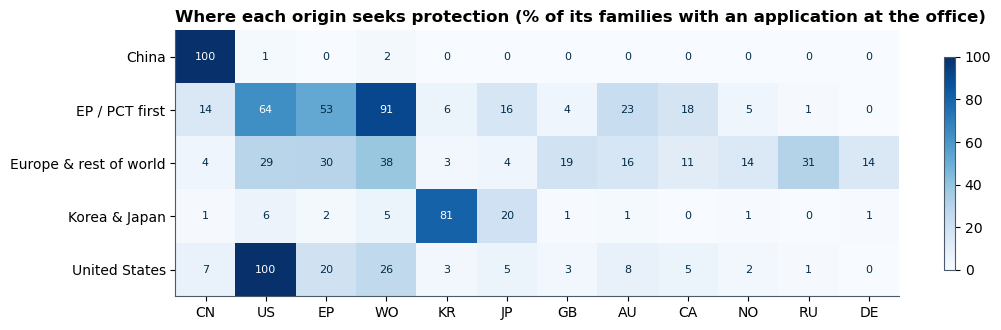

In [14]:
flows = fam_c[["docdb_family_id", "origin_group", "offices"]].assign(office=lambda d: d.offices.str.split()).explode("office")
dest = ["CN", "US", "EP", "WO", "KR", "JP", "GB", "AU", "CA", "NO", "RU", "DE"]
od = flows[flows.office.isin(dest)].pivot_table(index="origin_group", columns="office", values="docdb_family_id", aggfunc="nunique", fill_value=0)
od = od.div(fam_c.groupby("origin_group").size(), axis=0)[dest]
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(od.values * 100, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(dest)), dest); ax.set_yticks(range(len(od)), od.index)
for i in range(od.shape[0]):
    for j in range(od.shape[1]):
        v = od.iat[i, j] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else NAVY)
ax.set_title("Where each origin seeks protection (% of its families with an application at the office)")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save(fig, "s1_origin_destination"); plt.show()

## 1.5 Appropriability: is the field patent-heavy, or does it rely on secrecy?

**Theory (IM_Theory_0, IM_Theory_2).** Firms protect inventions with *formal* methods (patents) or *informal* ones
(secrecy, complexity, lead time, complementary assets). Patenting pays when the invention is easy to copy once on
the market and infringement can be detected; secrecy is best for what cannot be seen from the product. Large firms
use formal methods more than small ones; and in **defence**, public procurement is itself an appropriability
mechanism (the government commits to buy from the innovator, IM_Theory_0). Cohen, Nelson & Walsh (2000) and
Arundel (2001) find that in most manufacturing industries secrecy and lead time are rated *more* effective than
patents.

Patent data cannot observe secrecy directly, so we triangulate with five pieces of evidence:

1. **market leaders vs patent leaders**: if the firms that lead the market hold few patents, they appropriate in other ways;
2. **who patents**: a sector dominated by universities and public bodies (non-practicing entities, IM_Theory_2)
   patents for reasons other than exclusion (evaluation, subsidies, technology transfer);
3. **how much protection each patent buys**: internationalisation, grants, renewals (does the owner keep paying?);
4. **post-grant use**: oppositions, licences, transfers, litigation (IM_Theory_1–2: the right is *probabilistic*, its
   value is tested in court and in the market for technology);
5. **comparison with the neighbouring field and with the literature**.

### 1.5.1 Market leaders vs patent leaders

The market leaders of UUVs (Kongsberg, Teledyne, Saab, General Dynamics, L3Harris: about 58% of the market
according to MarkNtel, Step 0 literature note) against the patent leaders of the sector (families 2000–2025, all years: the same counts as the Step 0 guide).

In [15]:
grp = appl.groupby("applicant").agg(families=("docdb_family_id", "nunique"),
                                                              fractional=("weight", "sum"), country=("country", lambda s: s.mode().iat[0] if s.notna().any() else None))
grp["type"] = grp.index.map(prof.set_index("applicant")["type"])
grp["rank"] = grp["families"].rank(ascending=False, method="min").astype(int)
market_leaders = ["KONGSBERG", "TELEDYNE", "SAAB", "GENERAL DYNAMICS (BLUEFIN)", "L3HARRIS", "HUNTINGTON INGALLS (HYDROID)",
                  "EXAIL (ECA)", "OCEANEERING", "TKMS (ATLAS ELEKTRONIK)", "NAVAL GROUP", "BAE SYSTEMS", "HANWHA", CLIENT]
ml = grp.reindex(market_leaders)[["families", "country", "type", "rank"]]
ml.loc[:, "families"] = ml["families"].fillna(0)
top_patent = grp.sort_values("families", ascending=False).head(8)[["families", "country", "type", "rank"]]
display(top_patent)
ml

,families,country,type,rank
applicant,,,,
HARBIN ENGINEERING UNIVERSITY,1226,CN,university,1
CHINESE ACADEMY OF SCIENCES,804,CN,university,2
CHINA STATE SHIPBUILDING (CSSC),697,CN,firm,3
NORTHWESTERN POLYTECHNICAL UNIVERSITY,575,CN,university,4
ZHEJIANG UNIVERSITY,381,CN,university,5
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,223,CN,university,6
TIANJIN UNIVERSITY,199,CN,university,7
DALIAN MARITIME UNIVERSITY,165,CN,university,8


,families,country,type,rank
applicant,,,,
KONGSBERG,10,NO,firm,222
TELEDYNE,9,US,firm,241
SAAB,13,SE,firm,174
GENERAL DYNAMICS (BLUEFIN),4,US,firm,527
L3HARRIS,6,US,firm,348
HUNTINGTON INGALLS (HYDROID),2,US,firm,902
EXAIL (ECA),14,FR,firm,160
OCEANEERING,45,US,firm,47
TKMS (ATLAS ELEKTRONIK),96,DE,firm,17


### 1.5.2 Who patents? Practicing vs non-practicing entities

Share of the sector's families (fractional) by type of owner, by origin, over time. Universities and public research
organisations are NPEs: they patent to transfer knowledge (licences, spin-offs) and to be evaluated, not to protect
their own products (IM_Theory_2). A sector where NPEs own most patents has a patent count that overstates the
*commercial* inventive activity, and acquisition targets must be searched among the firms.

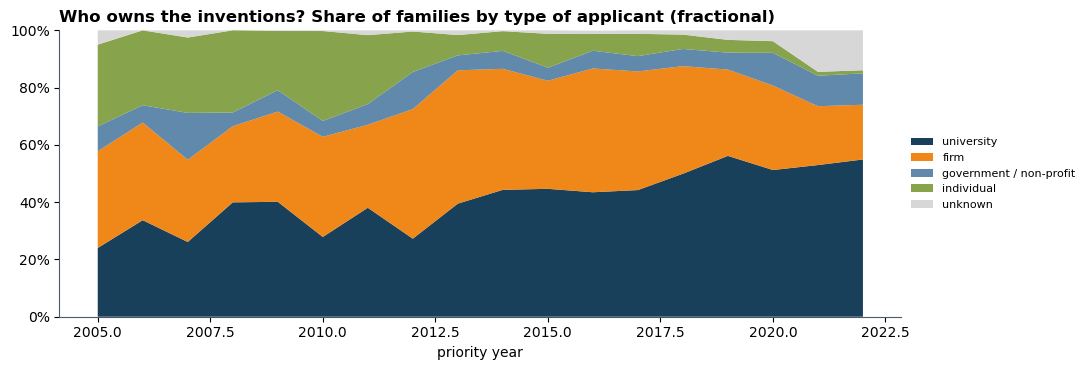

type,firm,government / non-profit,hospital,individual,university,unknown
origin_group,,,,,,
China,24.1%,6.9%,0.0%,3.2%,61.3%,4.5%
EP / PCT first,56.9%,5.6%,0.0%,15.0%,9.5%,13.0%
Europe & rest of world,48.2%,6.3%,0.0%,16.4%,14.9%,14.2%
Korea & Japan,53.4%,20.8%,0.0%,9.3%,13.7%,2.7%
United States,50.4%,12.5%,0.0%,24.0%,5.1%,8.0%
ALL,31.4%,8.4%,0.0%,6.5%,48.0%,5.6%


In [16]:
types = appl[appl.family_year <= LAST].merge(fam[["docdb_family_id", "origin_group"]], on="docdb_family_id")
tshare = types.pivot_table(index="origin_group", columns="type", values="weight", aggfunc="sum", fill_value=0)
tshare = tshare.div(tshare.sum(axis=1), axis=0)
tshare.loc["ALL"] = types.groupby("type")["weight"].sum() / types["weight"].sum()
ty = appl[appl.family_year.between(2005, LAST)].pivot_table(index="family_year", columns="type", values="weight", aggfunc="sum", fill_value=0)
ty = ty.div(ty.sum(axis=1), axis=0) * 100
KEY["share_university"] = float(tshare.loc["ALL"].get("university", 0)); KEY["share_firm"] = float(tshare.loc["ALL"].get("firm", 0))

fig, ax = plt.subplots(figsize=(11, 3.8))
order = [c for c in ["university", "firm", "government / non-profit", "individual", "unknown"] if c in ty.columns]
ax.stackplot(ty.index, ty[order].T.values, labels=order, colors=[NAVY, ORANGE, BLUE, GREEN, "lightgrey"], alpha=0.9)
ax.set(title="Who owns the inventions? Share of families by type of applicant (fractional)", xlabel="priority year", ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8, frameon=False)
plt.tight_layout(); save(fig, "s1_owner_types"); plt.show()
tshare.style.format("{:.1%}")

**"Unknown"** applicants are names PATSTAT could not classify (`psn_sector` empty): in this sector they are mostly
small Chinese technology companies (… TECHNOLOGY, … INTELLIGENT TECHNOLOGY). Treat them as firms in the deck only
after checking the largest ones by hand (`applicants_to_review.csv`).

### 1.5.3 How much protection does each patent buy?

By origin and by type of owner: share granted (families with priority ≤ 2019, so that most have been examined:
Tutorial 4, *the time window*), internationalisation, mean number of offices, share still alive (`active_proxy`,
the WIPO *active family* notion of IM_Theory_3), share with renewal fees paid, share lapsed, forward citations within
5 years (complete windows only). The two IM_Theory_2 hypotheses tested here: universities rarely go abroad (small
budgets), and Chinese families are cheaper, narrower and less renewed.

In [17]:
fam_types = types.groupby("docdb_family_id")["type"].agg(lambda s: s.value_counts().index[0])
fam["main_type"] = fam["docdb_family_id"].map(fam_types).fillna("unknown")
fam_c = fam[fam.family_year <= LAST]

def protection_profile(d):
    return pd.Series({"families": len(d), "granted (≤2019)": d.loc[d.family_year <= 2019, "granted_any"].mean(),
                      "international": d["is_international"].mean(), "mean offices": d["n_offices"].mean(),
                      "has EP": d["has_ep"].mean(), "active today": d.loc[d.family_year <= 2019, "active_proxy"].mean(),
                      "renewal fee paid (any)": d["ev_renewal_fee"].astype(str).str.lower().eq("true").mean(),
                      "fwd cits 5y (complete)": d.loc[d.fwd_window_complete, "fwd_cits_5y"].mean(),
                      "NPL share of backward cits": (d["bwd_npl_cits"].sum() / (d["bwd_npl_cits"].sum() + d["bwd_pat_cits_pub"].sum()))})

prot = pd.concat({"origin": fam_c.groupby("origin_group").apply(protection_profile),
                  "owner type": fam_c.groupby("main_type").apply(protection_profile)})
prot.loc[("sector", "all"), :] = protection_profile(fam_c)
prot.style.format({"families": "{:,.0f}", "granted (≤2019)": "{:.0%}", "international": "{:.0%}", "mean offices": "{:.2f}",
                   "has EP": "{:.0%}", "active today": "{:.0%}", "renewal fee paid (any)": "{:.1%}",
                   "fwd cits 5y (complete)": "{:.2f}", "NPL share of backward cits": "{:.1%}"})

### 1.5.4 Post-grant life: oppositions, licences, transfers, litigation

From the INPADOC legal events (`02_clean` §9). At the EPO about **5% of granted patents are opposed** (IM_Theory_1):
a sector well above it is litigious (patents block competitors), well below it is not (patents are not fought
over, consistent with weak appropriation through patents). Licences and transfers are the *market for technology*
(IM_Theory_2, choice 4). The flags come from regular expressions on the event descriptions (`02_clean` §9):
the last table lists the descriptions behind each flag, read it before quoting a number. Two flags are refined here:
**UPC opt-outs** are kept apart. They are not litigation but a strategic choice (IM_Theory_1, *Unitary Patent*):
the owner keeps its EP patent out of the Unified Patent Court, so it cannot be revoked centrally in one action.
Opting out is typical of owners who value their patents and fear central attacks.

In [18]:
ev = legal.copy()
for c in ["ev_opposition", "ev_licence", "ev_transfer", "ev_litigation", "ev_revocation"]:
    ev[c] = ev[c].astype(str).str.lower().eq("true")
# Refined flags (the check table below shows why): the 02_clean "litigation" regex matches the UPC opt-outs, and the
# "revocation" regex matches "INVALIDATED EUROPEAN PATENT", which national offices publish when an EP patent is not
# validated there (no translation / fee), not a court revocation.
d_ = ev["event_descr"].fillna("").str.upper()
ev["ev_upc_opt_out"] = d_.str.contains("OPT-OUT") & ~d_.str.contains("WITHDRAWAL OF OPT-OUT")
# US assignments also record the routine transfer from the inventors to their employer: keep a version without them
ev["ev_transfer_non_US"] = ev["ev_transfer"] & ev["event_auth"].ne("US")
ev["ev_litigation"] = ev["ev_litigation"] & ~d_.str.contains("OPT-OUT")
ev["ev_revocation"] = ev["ev_revocation"] & ~d_.str.contains("INVALIDATED EUROPEAN PATENT|INVALIDATION OF EXTENSION")
ev_fam = ev.groupby("docdb_family_id")[["ev_opposition", "ev_licence", "ev_transfer", "ev_litigation", "ev_revocation", "ev_upc_opt_out", "ev_transfer_non_US"]].any()
ep_granted = set(apps.loc[(apps.appln_auth == "EP") & apps.is_granted.astype(str).str.lower().eq("true"), "docdb_family_id"])
ep_opp = set(ev.loc[(ev.event_auth == "EP") & ev.ev_opposition, "docdb_family_id"])
post = pd.DataFrame({
    "families with the event": ev_fam.sum(),
    "share of all families": ev_fam.sum() / len(fam),
    "share of international families": ev_fam.reindex(list(SAMPLES["international"])).fillna(False).astype(bool).mean(),
})
opp_rate = len(ep_opp & ep_granted) / max(len(ep_granted), 1)
KEY["ep_opposition_rate"] = float(opp_rate)
print(f"EP-granted families: {len(ep_granted):,}; opposed at the EPO: {len(ep_opp & ep_granted):,} = {opp_rate:.1%} "
      f"(EPO average about 5%, IM_Theory_1)")
display(post.style.format({"families with the event": "{:,.0f}", "share of all families": "{:.2%}", "share of international families": "{:.2%}"}))
# CHECK the flags before quoting them: the most frequent event descriptions behind each flag (regex of 02_clean)
check = {c: ev.loc[ev[c], "event_descr"].value_counts().head(3).to_dict() for c in ["ev_opposition", "ev_litigation", "ev_revocation", "ev_licence", "ev_upc_opt_out"]}
pd.DataFrame([(k, d, n) for k, v in check.items() for d, n in v.items()], columns=["flag", "event description (tls803)", "events"])

EP-granted families: 341; opposed at the EPO: 12 = 3.5% (EPO average about 5%, IM_Theory_1)


,families with the event,share of all families,share of international families
ev_opposition,19,0.12%,1.20%
ev_licence,119,0.76%,3.31%
ev_transfer,"1,940",12.31%,64.26%
ev_litigation,7,0.04%,0.45%
ev_revocation,23,0.15%,1.50%
ev_upc_opt_out,131,0.83%,9.56%
ev_transfer_non_US,"1,049",6.66%,19.86%


,flag,event description (tls803),events
0,ev_opposition,OPPOSITION FILED,41
1,ev_opposition,NOTICE OF OPPOSITION AND REQUEST TO FILE OBSERVATION + T...,21
2,ev_opposition,OPPOSITION FILED AGAINST PATENT,21
3,ev_litigation,CLAIM OR COUNTERCLAIM FOR REVOCATION BEFORE THE COURT (S...,16
4,ev_litigation,AMENDMENT OF PATENT IN INFRINGEMENT OR REVOCATION PROCEE...,2
5,ev_litigation,CASE FILE PENDING WITH FEDERAL PATENT COURT,1
6,ev_revocation,CLAIM OR COUNTERCLAIM FOR REVOCATION BEFORE THE COURT (S...,16
7,ev_revocation,LT: INVALIDATION OF EUROPEAN PATENT OR PATENT EXTENSION,9
8,ev_revocation,EPO'S REVOCATION DECISION NOW FINAL,3
9,ev_licence,LICENCE RECORDED,89


### 1.5.5 Argued paragraph (draft, to complete with sources)

Fill the brackets with the numbers printed above (also in `key_numbers.json`) and check every claim on a source:

> *Underwater drones are a sector where patents measure **research effort** more than **market power**. Patent
> leadership is held by Chinese universities and state groups ([share]% of families owned by universities), while the
> firms that lead the market hold few families (Kongsberg [n], Saab [n], Teledyne [n]). [x]% of the families are
> filed in one office only, and Chinese families go abroad in [y]% of cases against [z]% for US-origin ones. Market
> leaders appropriate value mainly through **secrecy, system complexity and lead time**, and through
> **public procurement** in defence (IM_Theory_0; Cohen et al., 2000; Arundel, 2001): naval programmes can also be
> covered by secrecy orders, which keeps them out of patent data altogether. Patents are rarely fought over
> (EPO opposition rate [o]% vs about 5% on average). For the client this means two things: patent counts
> overstate Chinese and academic players, so Step 3 must weigh quality (citations, internationalisation), and the
> valuable know-how of a target sits partly outside its patent portfolio (people, software, contracts).*

# STEP 2 · Competitive landscape

## 2.1 Concentration: how concentrated is the field, and is it consolidating?

**Unit.** The applicant is the harmonised group of `02_clean` (three traceable layers, `applicants_audit.csv`):
without harmonisation a large firm splits into many small ones and every concentration measure is wrong
(Tutorial 1 nb 11 §2). **Counts.** *Inventive* concentration: the share of families held by each applicant
(full counting: a co-owned family counts for each owner, as in Tutorial 1), not market shares.

The six measures of Liston-Heyes & Pilkington (2004), Tutorial 1 nb 11 §3: CR4, CR8, Herfindahl–Hirschman (HH),
its numbers-equivalent 1/HH, coefficient of variation, Gini, Lotka slope.

In [19]:
def concentration_ratio(x, k):
    x = np.sort(np.asarray(x))[::-1]; return x[:k].sum() / x.sum()

def herfindahl(x):
    s = np.asarray(x, dtype=float) / np.sum(x); return float(np.sum(s ** 2))

def lorenz_curve(x):
    x = np.sort(np.asarray(x, dtype=float))
    return np.arange(0, len(x) + 1) / len(x), np.concatenate([[0], np.cumsum(x) / x.sum()])

def gini(x):
    f, p = lorenz_curve(x)
    return (0.5 - np.sum(np.diff(f) * (p[1:] + p[:-1]) / 2)) / 0.5

def lotka(x):
    f = pd.Series(x).value_counts().sort_index()
    if len(f) < 3:
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index.astype(float)), np.log(f.values.astype(float)))
    return fit.slope, fit.pvalue

def six_measures(x):
    x = np.asarray(x, dtype=float)
    L, p = lotka(np.round(x).astype(int)) if np.allclose(x, np.round(x)) else (np.nan, np.nan)
    return {"applicants": len(x), "families (sum)": x.sum(), "CR4": concentration_ratio(x, 4), "CR8": concentration_ratio(x, 8),
            "HH": herfindahl(x), "1/HH": 1 / herfindahl(x), "CV": x.std(ddof=1) / x.mean(), "Gini": gini(x),
            "Lotka L": L, "Lotka p": p}

links = appl[["docdb_family_id", "applicant", "type", "country", "weight", "family_year"]].drop_duplicates(["docdb_family_id", "applicant"])
links_c = links[links.family_year <= LAST]

conc = {}
for name, ids in SAMPLES.items():
    d = links_c[links_c.docdb_family_id.isin(ids)]
    conc[name] = six_measures(d.groupby("applicant")["docdb_family_id"].nunique())
conc["all · firms only"] = six_measures(links_c[links_c.type == "firm"].groupby("applicant")["docdb_family_id"].nunique())
conc["all · fractional counts"] = six_measures(links_c.groupby("applicant")["weight"].sum())
conc = pd.DataFrame(conc).T
KEY["HH_all"] = float(conc.loc["all", "HH"]); KEY["CR4_all"] = float(conc.loc["all", "CR4"])
KEY["one_over_HH_all"] = float(conc.loc["all", "1/HH"])
conc.style.format({"applicants": "{:,.0f}", "families (sum)": "{:,.0f}", "CR4": "{:.1%}", "CR8": "{:.1%}", "HH": "{:.4f}",
                   "1/HH": "{:,.1f}", "CV": "{:.2f}", "Gini": "{:.2f}", "Lotka L": "{:.2f}", "Lotka p": "{:.3f}"}, na_rep="–")

,applicants,families (sum),CR4,CR8,HH,1/HH,CV,Gini,Lotka L,Lotka p
all,"3,984","12,101",16.9%,21.7%,0.0099,101.5,6.19,0.62,-1.14,0.000
without block-6-only,"3,305","9,468",17.3%,22.4%,0.0106,94.4,5.83,0.60,-1.16,0.000
international,"1,266","2,133",7.2%,10.6%,0.0034,298.4,1.80,0.37,-1.79,0.000
all · firms only,"1,379","3,896",14.8%,19.1%,0.0098,101.6,3.55,0.56,-1.31,0.000
all · fractional counts,"3,984","9,969",20.1%,25.7%,0.0137,72.9,7.33,0.74,–,–


**Reading.** HH is far below 0.15 (the usual antitrust threshold for a *moderately* concentrated market): the
production of inventions is dispersed, with about 100 "equal-sized" applicants (1/HH). Three things to say on the
slide: (i) the Gini is high even when HH is low: many applicants with one or two families and a few very large
portfolios (Lotka slope flatter than the −2 of Lotka's law means more big portfolios than chance); (ii) the large
portfolios belong to universities, so firms-only concentration tells a different story about who could be bought;
(iii) among **international** families concentration is even lower: the value frontier is contested by many
players, a fragmented market for an acquirer.

### 2.1.1 Is the field consolidating? (the cell missing in Tutorial 1)

A field consolidates when fewer applicants account for more inventions over time: HH and CR4 rising, 1/HH falling.
Computed on windows of `WINDOW` = 3 priority years (one year alone is too small), for all families and for
international ones.

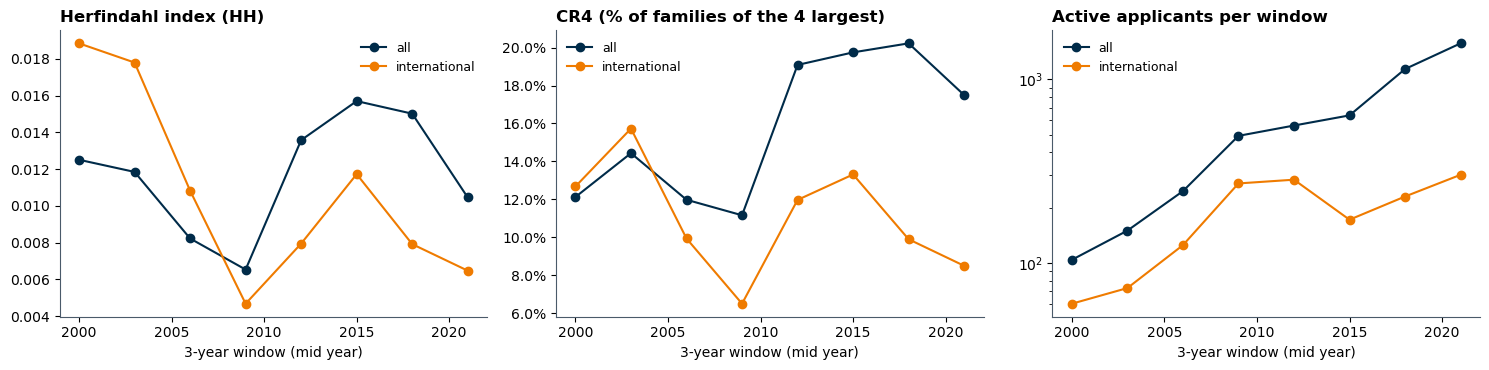

sample,window,mid,applicants,HH,1/HH,CR4,top-4 applicants
all,1999-2001,2000,104,0.0125,79.9,12.1%,"United States Of Ameri, Mitsubishi Heavy Indus, Total Marine Technolog, Mentor Subsea Technolo"
all,2002-2004,2003,150,0.0119,84.4,14.4%,"United States Of Ameri, Chinese Academy Of Sci, Tkms (Atlas Elektronik, Honeywell Internationa"
all,2005-2007,2006,246,0.0082,121.5,12.0%,"Chinese Academy Of Sci, Tkms (Atlas Elektronik, United States Of Ameri, Mitsui Engineering And"
all,2008-2010,2009,492,0.0065,153.0,11.2%,"Harbin Engineering Uni, Chinese Academy Of Sci, Tkms (Atlas Elektronik, China State Shipbuildi"
all,2011-2013,2012,560,0.0136,73.6,19.1%,"Chinese Academy Of Sci, Samsung Heavy Industri, Harbin Engineering Uni, Hanwha"
all,2014-2016,2015,636,0.0157,63.7,19.8%,"Harbin Engineering Uni, Chinese Academy Of Sci, China State Shipbuildi, Zhejiang University"
all,2017-2019,2018,1137,0.0150,66.6,20.2%,"Harbin Engineering Uni, Chinese Academy Of Sci, Northwestern Polytechn, China State Shipbuildi"
all,2020-2022,2021,1569,0.0105,95.6,17.5%,"Harbin Engineering Uni, Northwestern Polytechn, Chinese Academy Of Sci, China State Shipbuildi"
international,1999-2001,2000,60,0.0188,53.1,12.7%,"Mentor Subsea Technolo, Expro North Sea, Flight Refuelling, Hudson Steven Martin"
international,2002-2004,2003,73,0.0178,56.2,15.7%,"Tkms (Atlas Elektronik, Richter Ralf, Oceaneering, Lambertus Detlef"


In [20]:
def windows(end=LAST, size=WINDOW, n=8):
    """n consecutive windows of `size` years, the last one ending at the last complete year."""
    return [(e - size + 1, e) for e in range(end, end - size * n, -size)][::-1]

rows = []
for sample in ["all", "international"]:
    d0 = links[links.docdb_family_id.isin(SAMPLES[sample])]
    for a, b_ in windows():
        d = d0[d0.family_year.between(a, b_)]
        x = d.groupby("applicant")["docdb_family_id"].nunique()
        if len(x) < 5:
            continue
        rows.append({"sample": sample, "window": f"{a}-{b_}", "mid": (a + b_) / 2, "applicants": len(x),
                     "HH": herfindahl(x), "1/HH": 1 / herfindahl(x), "CR4": concentration_ratio(x, 4),
                     "top-4 applicants": ", ".join(x.sort_values(ascending=False).head(4).index.str.title().str[:22])})
cons = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for sample, c in [("all", NAVY), ("international", ORANGE)]:
    d = cons[cons["sample"] == sample]
    axes[0].plot(d["mid"], d["HH"], marker="o", color=c, label=sample)
    axes[1].plot(d["mid"], d["CR4"] * 100, marker="o", color=c, label=sample)
    axes[2].plot(d["mid"], d["applicants"], marker="o", color=c, label=sample)
axes[0].set(title="Herfindahl index (HH)", xlabel="3-year window (mid year)")
axes[1].set(title="CR4 (% of families of the 4 largest)", xlabel="3-year window (mid year)"); axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[2].set(title="Active applicants per window", xlabel="3-year window (mid year)"); axes[2].set_yscale("log")
for ax in axes: ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save(fig, "s2_concentration_over_time"); plt.show()
cons.style.format({"HH": "{:.4f}", "1/HH": "{:,.1f}", "CR4": "{:.1%}", "mid": "{:.0f}"}).hide(axis="index")

### 2.1.2 Concentration by country, and the Lorenz curves

The comparative design of Liston-Heyes & Pilkington (2004) on our sector: the measures computed separately on the
applicants of each country (applicant country, complete years), then countries ranked under each measure and the
agreement between rankings measured with Kendall's tau-b. Countries with at least 30 applicants only.

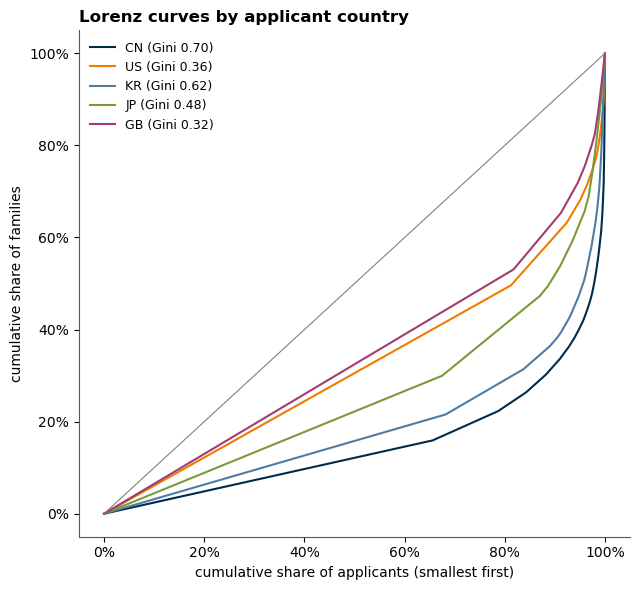

,applicants,families (sum),CR4,CR8,HH,1/HH,CV,Gini,Lotka L,Lotka p
CN,"1,977","8,156",25.1%,32.3%,0.021,48.0,6.34,0.70,-0.99,0.000
US,709,"1,161",13.8%,18.8%,0.009,109.7,2.34,0.36,-1.43,0.000
KR,264,835,33.5%,43.7%,0.037,26.9,2.97,0.62,-0.96,0.000
RU,138,278,23.7%,35.3%,0.024,42.0,1.52,0.44,-1.39,0.000
JP,123,277,31.0%,40.8%,0.032,31.3,1.72,0.48,-1.20,0.000
GB,148,228,20.2%,28.1%,0.017,58.9,1.23,0.32,-1.64,0.001
FR,89,212,35.4%,44.8%,0.040,25.0,1.61,0.49,-1.22,0.002
DE,64,206,60.7%,69.4%,0.174,5.8,3.21,0.65,-0.68,0.031
NO,89,164,31.7%,42.1%,0.039,25.6,1.58,0.41,-1.29,0.004
CA,52,69,20.3%,31.9%,0.027,37.5,0.63,0.21,-2.14,0.023


,CV,CR4,CR8,HH,Lotka L,Gini
CV,1.00,0.28,0.26,0.10,0.73,0.82
CR4,0.28,1.00,0.97,0.82,0.42,0.41
CR8,0.26,0.97,1.00,0.85,0.39,0.38
HH,0.10,0.82,0.85,1.00,0.27,0.23
Lotka L,0.73,0.42,0.39,0.27,1.00,0.82
Gini,0.82,0.41,0.38,0.23,0.82,1.00


In [21]:
by_ctry = {}
for ctry, d in links_c.groupby("country"):
    x = d.groupby("applicant")["docdb_family_id"].nunique()
    if len(x) >= 30:
        by_ctry[ctry] = six_measures(x)
by_ctry = pd.DataFrame(by_ctry).T.sort_values("families (sum)", ascending=False)
MEAS = ["CV", "CR4", "CR8", "HH", "Lotka L", "Gini"]
scores = by_ctry[MEAS].copy(); scores["Lotka L"] = -scores["Lotka L"].abs()
tau = pd.DataFrame(index=MEAS, columns=MEAS, dtype=float)
for a in MEAS:
    for b_ in MEAS:
        tau.loc[a, b_] = stats.kendalltau(scores[a], scores[b_], nan_policy="omit")[0]

fig, ax = plt.subplots(figsize=(6.5, 6))
for ctry, c in zip(["CN", "US", "KR", "JP", "GB"], PALETTE):
    x = links_c[links_c.country == ctry].groupby("applicant")["docdb_family_id"].nunique()
    if len(x):
        f_, p_ = lorenz_curve(x); ax.plot(f_, p_, color=c, label=f"{ctry} (Gini {gini(x):.2f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set(title="Lorenz curves by applicant country", xlabel="cumulative share of applicants (smallest first)", ylabel="cumulative share of families")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save(fig, "s2_lorenz_by_country"); plt.show()
display(by_ctry.style.format({"applicants": "{:,.0f}", "families (sum)": "{:,.0f}", "CR4": "{:.1%}", "CR8": "{:.1%}", "HH": "{:.3f}",
                              "1/HH": "{:,.1f}", "CV": "{:.2f}", "Gini": "{:.2f}", "Lotka L": "{:.2f}", "Lotka p": "{:.3f}"}, na_rep="–"))
tau.round(2)

## 2.2 The players: incumbents, entrants and the shortlist for Step 3

**Top applicants** with type, country, size, momentum and a first look at quality. Definitions (all design choices):

- **incumbent**: first family in the sector before `SPLIT_YEAR` (2015); **entrant**: from 2015 on;
- **momentum**: share of the sector's families in 2018–2022 minus share in 2013–2017 (percentage points);
- **influence preview**: forward citations within 5 years divided by the mean of the families of the same priority
  year (Tutorial 4 §5.1; complete 5-year windows only), averaged over the applicant's families: 1 = average;
- **international share**: share of the applicant's families filed at more than one office or via PCT.

In [22]:
fam["fwd5_norm"] = np.nan
ok = fam.fwd_window_complete
fam.loc[ok, "fwd5_norm"] = fam.loc[ok, "fwd_cits_5y"] / fam.loc[ok].groupby("family_year")["fwd_cits_5y"].transform("mean").replace(0, np.nan)
fl = links.merge(fam[["docdb_family_id", "is_international", "granted_any", "fwd5_norm", "n_offices"]], on="docdb_family_id")

tot_past = fam.family_year.between(*PAST).sum(); tot_rec = fam.family_year.between(*RECENT).sum()
g = fl.groupby("applicant")
players = pd.DataFrame({
    "type": g["type"].first(), "country": g["country"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None),
    "families": g["docdb_family_id"].nunique(), "fractional": g["weight"].sum(),
    "first year": g["family_year"].min(), "last year": g["family_year"].max(),
    f"families {RECENT[0]}-{RECENT[1]}": fl[fl.family_year.between(*RECENT)].groupby("applicant")["docdb_family_id"].nunique(),
    "momentum (pp)": (fl[fl.family_year.between(*RECENT)].groupby("applicant")["docdb_family_id"].nunique() / tot_rec
                      - fl[fl.family_year.between(*PAST)].groupby("applicant")["docdb_family_id"].nunique().reindex(g.size().index).fillna(0) / tot_past) * 100,
    "international share": g["is_international"].mean(), "mean offices": g["n_offices"].mean(),
    "granted share": g["granted_any"].mean(), "influence (fwd5, 1 = avg)": g["fwd5_norm"].mean(),
}).fillna({f"families {RECENT[0]}-{RECENT[1]}": 0})
players["share of sector"] = players["families"] / len(fam)
players["status"] = np.where(players["first year"] < SPLIT_YEAR, "incumbent", "entrant")
players["is client"] = players.index == CLIENT
players = players.sort_values("families", ascending=False)
players.to_csv(OUT / "players_all.csv")

FMT_P = {"families": "{:,.0f}", "fractional": "{:,.1f}", "first year": "{:.0f}", "last year": "{:.0f}",
         f"families {RECENT[0]}-{RECENT[1]}": "{:,.0f}", "momentum (pp)": "{:+.2f}", "international share": "{:.0%}",
         "mean offices": "{:.2f}", "granted share": "{:.0%}", "influence (fwd5, 1 = avg)": "{:.2f}", "share of sector": "{:.2%}"}
cols_show = ["type", "country", "families", "share of sector", "first year", "status", f"families {RECENT[0]}-{RECENT[1]}",
             "momentum (pp)", "international share", "influence (fwd5, 1 = avg)"]
short(players.head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–")

,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
HARBIN ENGINEERING UNIVERSITY,university,CN,"1,226",7.78%,2004,incumbent,508,-1.22,1%,1.17
CHINESE ACADEMY OF SCIENCES,university,CN,804,5.10%,2001,incumbent,329,-1.02,2%,0.68
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.42%,2007,incumbent,208,-0.11,0%,0.91
NORTHWESTERN POLYTECHNICAL UNIVERSITY,university,CN,575,3.65%,2010,incumbent,290,+1.91,0%,1.27
ZHEJIANG UNIVERSITY,university,CN,381,2.42%,2006,incumbent,165,+0.06,4%,1.32
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,223,1.42%,2013,incumbent,100,+0.25,5%,1.64
TIANJIN UNIVERSITY,university,CN,199,1.26%,2005,incumbent,85,+1.06,2%,1.03
DALIAN MARITIME UNIVERSITY,university,CN,165,1.05%,2013,incumbent,91,+1.03,2%,0.97
HOHAI UNIVERSITY,university,CN,158,1.00%,2010,incumbent,54,-0.52,4%,1.09


The overall ranking is a ranking of **Chinese universities**. For an acquirer that is not the relevant competitive
set: a university cannot be bought (it can be a *partner*, licensor or source of spin-offs, IM_Theory_2). The deck
table should therefore show three views: top firms worldwide, top firms outside China, and top universities /
public research organisations (potential partners).

In [23]:
firms = players[players.type.isin(["firm", "unknown"])]
display(short(firms.head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top firms (incl. unclassified companies)"))
display(short(firms[firms.country != "CN"].head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top firms outside China"))
short(players[players.type.isin(["university", "government / non-profit"])].head(10)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top universities and public research organisations")

,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.42%,2007,incumbent,208,-0.11,0%,0.91
CNOOC,firm,CN,102,0.65%,2007,incumbent,35,-0.29,0%,0.51
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.60,0%,0.46
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.56,95%,0.80
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.60,2%,0.27
CHINA THREE GORGES,firm,CN,60,0.38%,2012,incumbent,11,+0.17,2%,0.78
CHINA HUANENG GROUP,firm,CN,57,0.36%,2020,entrant,16,+0.25,4%,–
DEEPFAR OCEAN TECHNOLOGY,firm,CN,53,0.34%,2016,entrant,14,-0.54,4%,0.43
OCEANEERING,firm,US,45,0.29%,2000,incumbent,10,-0.65,76%,1.16


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.60,0%,0.46
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.56,95%,0.80
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.60,2%,0.27
OCEANEERING,firm,US,45,0.29%,2000,incumbent,10,-0.65,76%,1.16
BAE SYSTEMS,firm,GB,41,0.26%,2001,incumbent,18,+0.20,34%,0.83
THYSSEN KRUPP,firm,DE,40,0.25%,2014,incumbent,18,+0.04,98%,0.36
LIG NEX1,firm,KR,32,0.20%,2010,incumbent,17,+0.03,0%,0.27
IHI ISHIKAWAJIMA HARIMA HEAVY INDUSTRIES,firm,JP,29,0.18%,2008,incumbent,8,-0.32,10%,0.81
FEDERALNOE GOSUDARSTVENNOE KAZENNOE VOENNOE …,unknown,RU,26,0.17%,2016,entrant,22,+0.19,0%,0.04


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
HARBIN ENGINEERING UNIVERSITY,university,CN,"1,226",7.78%,2004,incumbent,508,-1.22,1%,1.17
CHINESE ACADEMY OF SCIENCES,university,CN,804,5.10%,2001,incumbent,329,-1.02,2%,0.68
NORTHWESTERN POLYTECHNICAL UNIVERSITY,university,CN,575,3.65%,2010,incumbent,290,+1.91,0%,1.27
ZHEJIANG UNIVERSITY,university,CN,381,2.42%,2006,incumbent,165,+0.06,4%,1.32
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,223,1.42%,2013,incumbent,100,+0.25,5%,1.64
TIANJIN UNIVERSITY,university,CN,199,1.26%,2005,incumbent,85,+1.06,2%,1.03
DALIAN MARITIME UNIVERSITY,university,CN,165,1.05%,2013,incumbent,91,+1.03,2%,0.97
HOHAI UNIVERSITY,university,CN,158,1.00%,2010,incumbent,54,-0.52,4%,1.09
OCEAN UNIVERSITY OF CHINA,university,CN,157,1.00%,2008,incumbent,67,+0.13,2%,1.38


**Start-ups.** The kick-off asks for the applicant type *firm / start-up / university*, but `psn_sector` has no
start-up category. Offline proxy (to verify by hand on company websites / Crunchbase): a **young firm** is a firm
whose first family in the sector is from 2015 on, with at most 30 families, not part of a large group in
`GROUP_ALIASES`. On TIP, the optional cell below refines it with the year of the **first patent ever, in any field**
(Tutorial 1 nb 11 §5.0: "they never patented before").

Read the list with care: the proxy also catches **large incumbents of other industries** that enter the sector late
(power grids, oil majors, rail-equipment makers). They are *diversifying entrants*, not start-ups, and they are a
finding in themselves (who is moving into underwater drones, and from where). The first-patent-ever refinement
separates the two groups.

In [24]:
big_groups = set(C.GROUP_ALIASES.values())
players["young firm (start-up candidate)"] = (players.type.isin(["firm", "unknown"]) & (players["first year"] >= SPLIT_YEAR)
                                              & (players["families"] <= 30) & ~players.index.isin(big_groups))
young = players[players["young firm (start-up candidate)"]].head(15)
print(f"{players['young firm (start-up candidate)'].sum():,} young firms; the largest:")
short(young[["country", "families", "first year", "international share", "influence (fwd5, 1 = avg)"]]).style.format(FMT_P, na_rep="–")

2,329 young firms; the largest:


,country,families,first year,international share,"influence (fwd5, 1 = avg)"
applicant,,,,,
SGCC STATE GRID CORPORATION OF CHINA,CN,30,2015,0%,3.04
ZHUZHOU CRRC TIMES ELECTRIC,CN,28,2019,7%,–
FEDERALNOE GOSUDARSTVENNOE KAZENNOE VOENNOE …,RU,26,2016,0%,0.04
GUANGDONG POWER GRID,CN,26,2020,0%,–
KUNMING HAIWEI ELECTROMECHANICAL TECHNOLOGY …,CN,24,2019,0%,–
HANGZHOU CHANGDONG INTELLIGENT TECHNOLOGY,CN,22,2016,5%,0.38
DONGGUAN QIQU ROBOT TECHNOLOGY,CN,21,2018,0%,–
ARTIFICIAL INTELLIGENCE ROBOT,KR,20,2017,5%,0.14
QINGDAO PENGPAI OCEAN EXPLORATION TECHNOLOGY,CN,19,2019,0%,–


In [25]:
if RUN_PATSTAT:   # TIP only: first patent ever (any field) of the top applicants, from their PATSTAT names
    from epo.tipdata.patstat import PatstatClient
    from epo.tipdata.patstat.database.models import TLS201_APPLN, TLS206_PERSON, TLS207_PERS_APPLN
    from sqlalchemy import func
    patstat = PatstatClient(env=C.ENV); db = patstat.orm()
    raw = appl.drop_duplicates("applicant").set_index("applicant")["raw_names"].dropna()
    names = {n.strip(): grp_name for grp_name, s in raw.loc[raw.index.isin(players.head(300).index)].items() for n in s.split("|")}
    q = (db.query(TLS206_PERSON.psn_name, func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
         .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
         .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
         .filter(TLS206_PERSON.psn_name.in_(list(names)), TLS207_PERS_APPLN.applt_seq_nr > 0,
                 TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))
         .group_by(TLS206_PERSON.psn_name))
    first_ever = patstat.df(q).assign(applicant=lambda d: d.psn_name.map(names)).groupby("applicant")["first_patent_year"].min()
    players["first patent ever"] = first_ever
    players.to_csv(OUT / "players_all.csv")
else:
    print("RUN_PATSTAT = False: first-patent-ever not queried (run on TIP to refine the start-up flag)")

RUN_PATSTAT = False: first-patent-ever not queried (run on TIP to refine the start-up flag)


### 2.2.1 Shortlist for Step 3 (present score)

The players worth scoring: **firms** (including unclassified companies) with at least `MIN_FAMILIES_SCORE` families
in the sector (a volume gate, as in Clarivate and Tutorial 4), plus the client as a reference point. Saved as
`shortlist_step3.csv`. The choice of gate is a design decision to justify in the appendix.

In [26]:
shortlist = players[(players.type.isin(["firm", "unknown"]) & (players.families >= MIN_FAMILIES_SCORE)) | players["is client"]]
shortlist.to_csv(OUT / "shortlist_step3.csv")
KEY["shortlist_size"] = int(len(shortlist))
print(f"{len(shortlist)} applicants in the shortlist ({(shortlist.country != 'CN').sum()} outside China); client included: {CLIENT in shortlist.index}")
short(shortlist.head(25)[cols_show]).style.format(FMT_P, na_rep="–")

99 applicants in the shortlist (41 outside China); client included: True


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.42%,2007,incumbent,208,-0.11,0%,0.91
CNOOC,firm,CN,102,0.65%,2007,incumbent,35,-0.29,0%,0.51
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.60,0%,0.46
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.56,95%,0.80
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.60,2%,0.27
CHINA THREE GORGES,firm,CN,60,0.38%,2012,incumbent,11,+0.17,2%,0.78
CHINA HUANENG GROUP,firm,CN,57,0.36%,2020,entrant,16,+0.25,4%,–
DEEPFAR OCEAN TECHNOLOGY,firm,CN,53,0.34%,2016,entrant,14,-0.54,4%,0.43
OCEANEERING,firm,US,45,0.29%,2000,incumbent,10,-0.65,76%,1.16


## 2.3 Entry and exit, year by year

As in Tutorial 1 nb 11 §5.2: for each priority year, the active applicants, those **new to the sector** (first
family in the sector that year), the **entrants' share of families** (families with at least one applicant new to
the sector) and the **rate of disappearance** (share of the year's active applicants that never file again in the
sector; shown only up to `LAST − 3`, because an applicant silent in the last years may simply not be published yet).
In the first years almost everyone looks new (families before 2000 are not seen): read entry from about 2005.

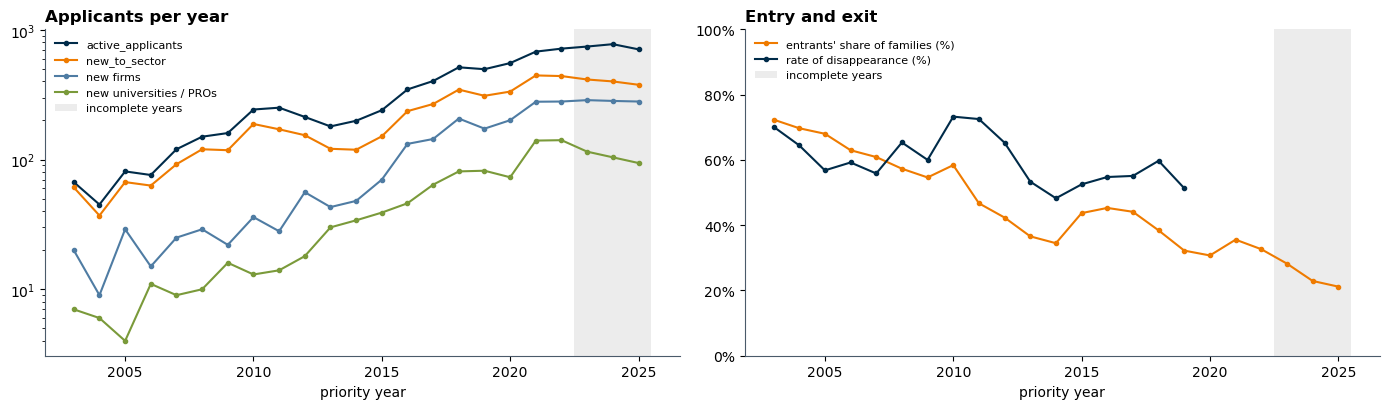

,active_applicants,new_to_sector,leaving,new firms,new universities / PROs,rate of disappearance (%),entrants' share of families (%)
year,,,,,,,
2003,67,61,47,20,7,70.1,72.3
2004,45,37,29,9,6,64.4,69.7
2005,81,67,46,29,4,56.8,68.0
2006,76,63,45,15,11,59.2,63.0
2007,120,92,67,25,9,55.8,60.9
2008,150,120,98,29,10,65.3,57.3
2009,160,118,96,22,16,60.0,54.6
2010,243,188,178,36,13,73.3,58.4
2011,251,171,182,28,14,72.5,46.7


In [27]:
first_year = links.groupby("applicant")["family_year"].min(); last_year = links.groupby("applicant")["family_year"].max()
active = links[["applicant", "family_year", "type"]].rename(columns={"family_year": "year"}).drop_duplicates(["applicant", "year"])
active["new"] = active["year"] == active["applicant"].map(first_year)
active["leaving"] = active["year"] == active["applicant"].map(last_year)
ee = active.groupby("year").agg(active_applicants=("applicant", "size"), new_to_sector=("new", "sum"), leaving=("leaving", "sum"))
ee["new firms"] = active[active.type.isin(["firm", "unknown"])].groupby("year")["new"].sum()
ee["new universities / PROs"] = active[active.type.isin(["university", "government / non-profit"])].groupby("year")["new"].sum()
ee["rate of disappearance (%)"] = ee["leaving"] / ee["active_applicants"] * 100
ee.loc[ee.index > LAST - 3, "rate of disappearance (%)"] = np.nan
ln = links.assign(new=links["family_year"] == links["applicant"].map(first_year))
ee["entrants' share of families (%)"] = ln.groupby(["family_year", "docdb_family_id"])["new"].any().groupby("family_year").mean() * 100
ee = ee.loc[2003:YEAR_MAX]
KEY["entrants_share_last5"] = float(ee.loc[LAST - 4:LAST, "entrants' share of families (%)"].mean() / 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ee[["active_applicants", "new_to_sector", "new firms", "new universities / PROs"]].plot(ax=axes[0], marker="o", ms=3, color=[NAVY, ORANGE, BLUE, GREEN])
axes[0].set(title="Applicants per year", xlabel="priority year"); axes[0].set_yscale("log")
ee[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3, color=[ORANGE, NAVY])
axes[1].set(title="Entry and exit", xlabel="priority year", ylim=(0, 100)); axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes: shade(ax); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "s2_entry_exit"); plt.show()
ee.round(1)

**Persistence.** Most applicants appear once and disappear. The share of applicants active in at least 3 distinct
years, by type, separates the *persistent* innovators (Patel & Pavitt, 1997: competences are path-dependent) from
occasional filers.

In [28]:
persist = links.groupby(["applicant"]).agg(type=("type", "first"), years_active=("family_year", "nunique"), families=("docdb_family_id", "nunique"))
pers = persist.groupby("type").agg(applicants=("years_active", "size"), share_active_3plus_years=("years_active", lambda s: (s >= 3).mean()),
                                   share_one_family=("families", lambda s: (s == 1).mean()))
pers.style.format({"applicants": "{:,.0f}", "share_active_3plus_years": "{:.1%}", "share_one_family": "{:.1%}"})

,applicants,share_active_3plus_years,share_one_family
type,,,
firm,"1,690",12.0%,63.6%
government / non-profit,386,16.8%,59.6%
hospital,2,0.0%,50.0%
individual,"1,250",1.1%,86.7%
university,776,27.6%,50.3%
unknown,"1,071",2.6%,77.6%


## 2.4 Subfields: which parts of the sector grow fastest?

Two independent definitions of a subfield, as the kick-off suggests (*"growth of CPC groups, or topics from
abstracts"*). If both point to the same growth areas, the result is robust to the definition.

### 2.4.1 CPC main groups: growth map and maturity matrix

A subfield = a CPC main group (e.g. `G05D1/`, `G06N3/`), allocation codes only (the Y and 2000-series indexing
codes are kept apart, except `B63G2008/` which names the unmanned vessels themselves). Families counted once per
subfield. Growth = families in 2018–2022 vs 2013–2017. Only subfields with at least 30 recent families are mapped,
so tiny groups with huge percentages do not win (Tutorial 1 nb 11 §5.3).

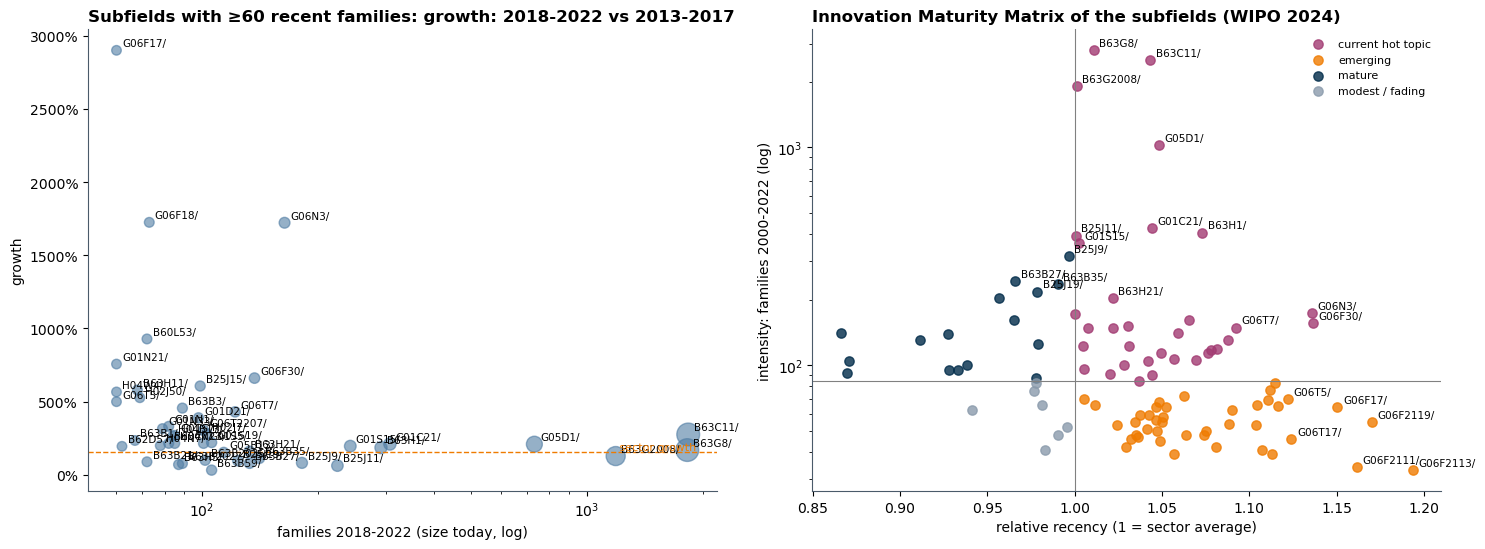

,families 2013-2017,families 2018-2022,growth (%),growth vs sector (pp),intensity (families ≤ 2022),relative recency,title (verify),maturity quadrant
main_group,,,,,,,,
B63C11/,488,"1,835",+276%,+120,"2,527",1.04,Equipment for working under water; searching for underwater objects,current hot topic
B63G8/,677,"1,825",+170%,+14,"2,793",1.01,"Underwater vessels, e.g. submarines",current hot topic
B63G2008/,520,"1,189",+129%,-27,"1,909",1.00,Unmanned underwater vessels (indexing),current hot topic
G05D1/,236,731,+210%,+54,"1,026",1.05,"Control of position, course, altitude or attitude of vehicles",current hot topic
G01C21/,99,308,+211%,+55,426,1.04,Navigation,current hot topic
B63H1/,102,292,+186%,+31,407,1.07,Propulsive elements (marine),current hot topic
G01S15/,82,243,+196%,+41,365,1.00,Sonar systems,current hot topic
B25J11/,138,225,+63%,-93,394,1.00,Manipulators not otherwise provided for,current hot topic
B25J9/,100,182,+82%,-74,318,1.00,Programme-controlled manipulators,mature


In [29]:
MAIN_GROUP_TITLES = {   # short titles: VERIFY on the CPC scheme
    "B63G8/": "Underwater vessels, e.g. submarines", "B63C11/": "Equipment for working under water; searching for underwater objects",
    "B63G2008/": "Unmanned underwater vessels (indexing)", "G05D1/": "Control of position, course, altitude or attitude of vehicles",
    "G01C21/": "Navigation", "G06N3/": "Neural networks / biological computing models", "G01S15/": "Sonar systems",
    "B25J9/": "Programme-controlled manipulators", "G06V10/": "Image or video recognition (general)", "B63H1/": "Propulsive elements (marine)",
    "G06F30/": "Computer-aided design / simulation", "G06T7/": "Image analysis", "B25J11/": "Manipulators not otherwise provided for",
    "B63B27/": "Ship-based loading / launching equipment (check)", "G06F18/": "Pattern recognition", "H02J7/": "Battery charging / supply",
    "B25J19/": "Manipulator accessories (sensors, safety)", "G01V1/": "Seismology / seismic prospecting", "B63B35/": "Vessels for special purposes",
    "H04N23/": "Cameras", "B63H21/": "Marine propulsion power plants", "H04B13/": "Transmission via water (acoustic/optical)",
    "H04B11/": "Underwater acoustic communication (check)", "G01S7/": "Details of sonar/radar systems", "G01S5/": "Position-fixing",
    "G05B13/": "Adaptive control systems", "G05B17/": "Systems involving models / simulation", "B08B1/": "Cleaning with tools",
    "B63B79/": "Monitoring properties or operating parameters of vessels", "G01N33/": "Investigating materials (water analysis…)",
    "B63B22/": "Buoys", "H01M50/": "Battery constructional details (check)", "H01M10/": "Secondary batteries", "F42B19/": "Marine torpedoes", "H01M6/": "Primary batteries", "G06F17/": "Digital computing / data processing (check)", "B63G9/": "Other offensive or defensive arrangements on vessels", "B63B21/": "Tying-up; towing; anchoring",
    "B63C7/": "Salvaging of disabled, stranded or sunken vessels", "B63H25/": "Steering; slowing-down", "B63B1/": "Hull shape",
}
mg = fcpc[(~fcpc.is_tagging.astype(str).str.lower().eq("true")) | fcpc.main_group.eq("B63G2008/")]
mg = mg[~mg.main_group.str.startswith("Y")].drop_duplicates(["docdb_family_id", "main_group"]).merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id")
past = mg[mg.family_year.between(*PAST)].groupby("main_group")["docdb_family_id"].nunique()
recent = mg[mg.family_year.between(*RECENT)].groupby("main_group")["docdb_family_id"].nunique()
sf = pd.DataFrame({f"families {PAST[0]}-{PAST[1]}": past, f"families {RECENT[0]}-{RECENT[1]}": recent}).fillna(0)
sf["growth (%)"] = (sf.iloc[:, 1] / sf.iloc[:, 0].replace(0, np.nan) - 1) * 100
sector_growth = (tot_rec / tot_past - 1) * 100
sf["growth vs sector (pp)"] = sf["growth (%)"] - sector_growth

# relative recency (WIPO maturity matrix), complete years 2000-LAST
def recency(yearly, start=YEAR_MIN, end=LAST):
    w = yearly.reindex(range(start, end + 1), fill_value=0).values.astype(float)
    i = np.arange(1, len(w) + 1); n = len(w)
    return (w * i).sum() / (n * w.sum()) if w.sum() else np.nan

R_sector = recency(fam.groupby("family_year").size())
mg_c = mg[mg.family_year <= LAST]
sf["intensity (families ≤ 2022)"] = mg_c.groupby("main_group")["docdb_family_id"].nunique()
sf["relative recency"] = mg_c.groupby("main_group").apply(lambda d: recency(d.groupby("family_year")["docdb_family_id"].nunique())) / R_sector
sf["title (verify)"] = [MAIN_GROUP_TITLES.get(i, "") for i in sf.index]
mapped = sf[sf.iloc[:, 1] >= 30].sort_values(sf.columns[1], ascending=False)

med_int = mapped["intensity (families ≤ 2022)"].median()
def quadrant(r):
    hi, rec_ = r["intensity (families ≤ 2022)"] >= med_int, r["relative recency"] >= 1
    return "current hot topic" if hi and rec_ else "emerging" if rec_ else "mature" if hi else "modest / fading"
mapped["maturity quadrant"] = mapped.apply(quadrant, axis=1)
mapped.to_csv(OUT / "subfields_cpc.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
ax = axes[0]
gm = mapped[mapped.iloc[:, 1] >= 60]          # the map shows the subfields with at least 60 recent families
ax.scatter(gm.iloc[:, 1], gm["growth (%)"], s=40 + gm.iloc[:, 1] / 8, color=BLUE, alpha=0.6)
for name, r in gm.iterrows():
    ax.annotate(name, (r.iloc[1], r["growth (%)"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax.axhline(sector_growth, color=ORANGE, ls="--", lw=1); ax.text(ax.get_xlim()[1], sector_growth, " sector growth", color=ORANGE, fontsize=8, va="bottom", ha="right")
ax.set_xscale("log"); ax.set(title=f"Subfields with ≥60 recent families: growth: {RECENT[0]}-{RECENT[1]} vs {PAST[0]}-{PAST[1]}", xlabel="families 2018-2022 (size today, log)", ylabel="growth")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax = axes[1]
qc = {"current hot topic": RED, "emerging": ORANGE, "mature": NAVY, "modest / fading": MID}
for qn, d in mapped.groupby("maturity quadrant"):
    ax.scatter(d["relative recency"], d["intensity (families ≤ 2022)"], color=qc[qn], label=qn, s=45, alpha=0.8)
lab = pd.concat([mapped.head(16), mapped[mapped["maturity quadrant"].eq("emerging")].sort_values("relative recency", ascending=False).head(6)])
for name, r in lab.iterrows():
    ax.annotate(name, (r["relative recency"], r["intensity (families ≤ 2022)"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax.axvline(1, color="grey", lw=0.8); ax.axhline(med_int, color="grey", lw=0.8); ax.set_yscale("log")
ax.set(title="Innovation Maturity Matrix of the subfields (WIPO 2024)", xlabel="relative recency (1 = sector average)", ylabel="intensity: families 2000-2022 (log)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "s2_subfield_growth_maturity"); plt.show()
mapped.head(25).style.format({mapped.columns[0]: "{:,.0f}", mapped.columns[1]: "{:,.0f}", "growth (%)": "{:+.0f}%", "growth vs sector (pp)": "{:+.0f}",
                              "intensity (families ≤ 2022)": "{:,.0f}", "relative recency": "{:.2f}"}, na_rep="–")

### 2.4.2 Topics from the abstracts

The CPC is the examiners' view and lags behind new technologies. Topics from the text are the applicants' view.
Offline version: **TF-IDF + NMF** (non-negative matrix factorisation) on the cleaned English abstracts of
`02_clean` (`clean_abstract`): transparent (each topic is a list of weighted words), fast on CPU, and in the family
of TF-IDF encodings of Tutorial 2 nb 21 §3. The TIP version with **Patent SBERT + BERTopic** (Tutorial 2 nb 21
§9.3) is in the optional cell further down: run it and compare the two sets of topics in the appendix.
Topics are named by hand from their words: **read 5 abstracts per topic before naming it.**

In [30]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

N_TOPICS = 14
SECTOR_WORDS = {"underwater", "vehicle", "vehicles", "robot", "unmanned", "body", "unit", "module", "provided", "connected",
                "end", "side", "plate", "fixedly", "fixed", "arranged", "mounted", "rod", "utility", "model", "shell", "connecting"}
PATENT_STOP = {"said", "wherein", "comprising", "comprises", "invention", "method", "device", "apparatus", "system", "according",
               "plurality", "includes", "including", "first", "second", "third", "present", "disclosed", "provides", "relates", "based"}
docs = fam.loc[fam.clean_abstract.notna() & (fam.clean_abstract.str.len() > 40)].copy()
tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | SECTOR_WORDS | PATENT_STOP), ngram_range=(1, 2), min_df=10, max_df=0.4, sublinear_tf=True)
X = tfidf.fit_transform(docs.clean_abstract)
nmf = NMF(n_components=N_TOPICS, random_state=42, init="nndsvda", max_iter=400)
Wd = nmf.fit_transform(X)
terms = np.array(tfidf.get_feature_names_out())
topic_words = {k: ", ".join(terms[nmf.components_[k].argsort()[::-1][:9]]) for k in range(N_TOPICS)}
docs["topic"] = Wd.argmax(axis=1)
docs["topic_strength"] = Wd.max(axis=1)
docs.loc[docs.topic_strength < 1e-3, "topic"] = -1    # documents that load on no topic
print(f"{X.shape[0]:,} abstracts x {X.shape[1]:,} terms; {(docs.topic == -1).mean():.1%} without a topic")
topics = pd.DataFrame({"top words": topic_words, "families": docs[docs.topic >= 0].groupby("topic").size()})
topics["name (fill in by hand)"] = ""
topics

15,606 abstracts x 16,337 terms; 0.0% without a topic


,top words,families,name (fill in by hand)
0,"frame, supporting, fixing, mounting, upper, guide, assem...",877,
1,"image, data, detection, target, processing, sonar, infor...",1748,
2,"fish, robotic, robotic fish, bionic, fin, tail, bionic r...",824,
3,"power, supply, power supply, communication, charging, en...",1209,
4,"control, tracking, controller, trajectory, state, error,...",1100,
5,"pressure, valve, oil, water, pump, air, tank, buoyancy, bag",1306,
6,"path, planning, path planning, obstacle, algorithm, avoi...",802,
7,"navigation, positioning, position, information, measurem...",1303,
8,"cable, rov, operated, remotely, remotely operated, surfa...",1606,
9,"cabin, main, propeller, adjusting, buoyancy, propellers,...",1348,


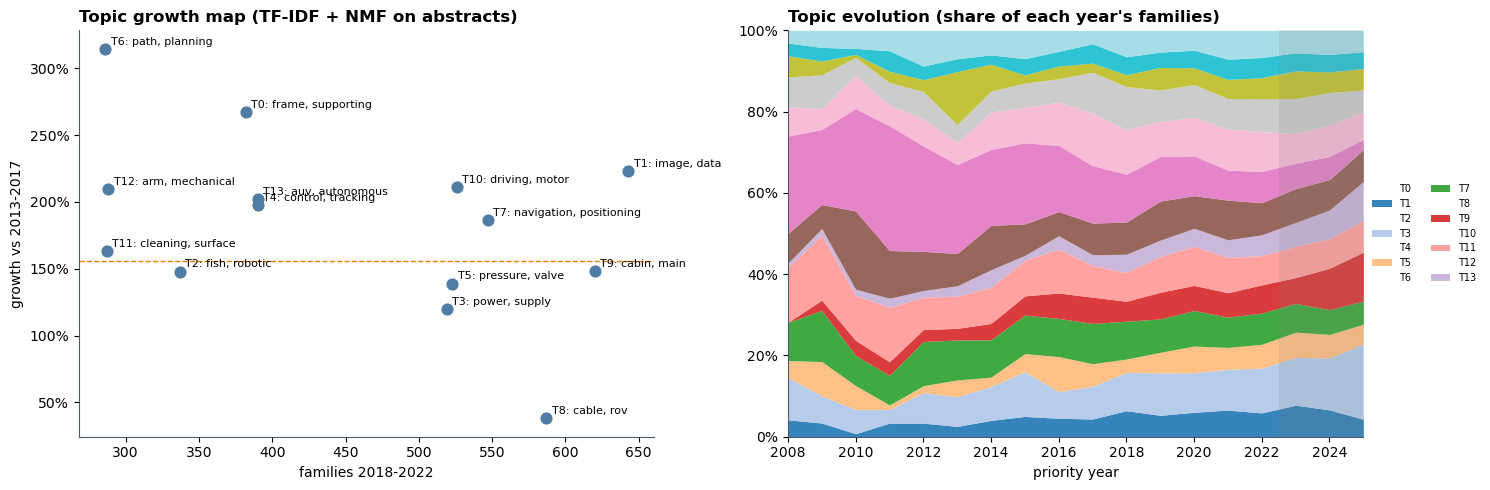

,families past,families recent,growth (%),relative recency,international share,China share (first filing),top words
topic,,,,,,,
6,69,286,+314%,1.07,3%,95%,"path, planning, path planning, obstacle, algorithm, avoidance, environment, optimization, obstacle avoidance"
0,104,382,+267%,1.04,2%,95%,"frame, supporting, fixing, mounting, upper, guide, assembly, lower, structure"
1,199,643,+223%,1.03,6%,86%,"image, data, detection, target, processing, sonar, information, network, feature"
10,169,526,+211%,1.02,6%,88%,"driving, motor, shaft, mechanism, rotating, gear, rotate, drive, driving mechanism"
12,93,288,+210%,1.03,7%,87%,"arm, mechanical, mechanical arm, operation, joint, grabbing, arms, manipulator, freedom"
13,129,390,+202%,1.02,10%,82%,"auv, autonomous, docking, recovery, auv autonomous, auvs, autonomous auv, station, butt joint"
4,131,390,+198%,1.05,3%,96%,"control, tracking, controller, trajectory, state, error, motion, trajectory tracking, disturbance"
7,191,547,+186%,1.00,6%,82%,"navigation, positioning, position, information, measurement, inertial, acoustic, inertial navigation, precision"
11,109,287,+163%,1.02,7%,79%,"cleaning, surface, cleaning cleaning, water, ship, cleaned, brush, hull, frame"


In [31]:
tp = docs[docs.topic >= 0]
tpast = tp[tp.family_year.between(*PAST)].groupby("topic").size(); trec = tp[tp.family_year.between(*RECENT)].groupby("topic").size()
tg = pd.DataFrame({"families past": tpast, "families recent": trec}).fillna(0)
tg["growth (%)"] = (tg["families recent"] / tg["families past"].replace(0, np.nan) - 1) * 100
tg["relative recency"] = tp[tp.family_year <= LAST].groupby("topic").apply(lambda d: recency(d.groupby("family_year").size())) / R_sector
tg["international share"] = tp.groupby("topic")["is_international"].mean()
tg["China share (first filing)"] = tp.groupby("topic")["first_office"].apply(lambda s: (s == "CN").mean())
tg["top words"] = tg.index.map(topic_words)
topic_share = tp[tp.family_year.between(2008, YEAR_MAX)].pipe(lambda d: pd.crosstab(d.family_year, d.topic, normalize="index")) * 100
tg.to_csv(OUT / "subfields_topics.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.scatter(tg["families recent"], tg["growth (%)"], s=60, color=BLUE)
for k, r in tg.iterrows():
    ax.annotate(f"T{k}: {topic_words[k].split(', ')[0]}, {topic_words[k].split(', ')[1]}", (r["families recent"], r["growth (%)"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.axhline(sector_growth, color=ORANGE, ls="--", lw=1)
ax.set(title="Topic growth map (TF-IDF + NMF on abstracts)", xlabel="families 2018-2022", ylabel="growth vs 2013-2017"); ax.yaxis.set_major_formatter(PercentFormatter(100))
ax = axes[1]
topic_share.plot.area(ax=ax, cmap="tab20", alpha=0.9, lw=0, legend=False)
shade(ax); ax.set(title="Topic evolution (share of each year's families)", xlabel="priority year", ylim=(0, 100), xlim=(2008, YEAR_MAX))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.legend([f"T{k}" for k in topic_share.columns], ncol=2, fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); save(fig, "s2_topics"); plt.show()
tg.sort_values("growth (%)", ascending=False).style.format({"families past": "{:,.0f}", "families recent": "{:,.0f}", "growth (%)": "{:+.0f}%",
                                                           "relative recency": "{:.2f}", "international share": "{:.0%}", "China share (first filing)": "{:.0%}"})

**Do CPC and text agree?** Cross-tabulate the topics with the largest CPC subclasses: a topic that spreads over many
CPC subclasses is a *cross-cutting* subfield the classification does not see (e.g. path planning: G05D, G01C, G06N).

In [32]:
top10_sub = share_by(sub_c, "subclass", top=10).index.drop("Other")
ct = tp[["docdb_family_id", "topic"]].merge(fsub[fsub.subclass.isin(top10_sub)], on="docdb_family_id")
ct = ct.pivot_table(index="topic", columns="subclass", values="weight", aggfunc="sum", fill_value=0)
ct = ct.div(ct.sum(axis=1), axis=0)[list(top10_sub)]
ct.index = [f"T{k}: {topic_words[k][:40]}" for k in ct.index]
ct.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

subclass,B63G,B63C,G05D,B63B,B63H,G01S,G01C,B25J,G05B,Y02A
"T0: frame, supporting, fixing, mounting, upp",22%,44%,0%,21%,2%,1%,0%,5%,1%,4%
"T1: image, data, detection, target, processi",13%,14%,16%,3%,1%,20%,8%,3%,6%,17%
"T2: fish, robotic, robotic fish, bionic, fin",17%,24%,4%,3%,33%,1%,1%,6%,4%,5%
"T3: power, supply, power supply, communicati",28%,25%,9%,7%,7%,6%,1%,5%,9%,2%
"T4: control, tracking, controller, trajector",5%,3%,53%,1%,1%,1%,1%,2%,33%,1%
"T5: pressure, valve, oil, water, pump, air,",43%,26%,2%,13%,6%,1%,1%,3%,1%,4%
"T6: path, planning, path planning, obstacle,",3%,2%,56%,1%,0%,4%,21%,2%,4%,7%
"T7: navigation, positioning, position, infor",7%,5%,7%,3%,0%,28%,39%,1%,1%,9%
"T8: cable, rov, operated, remotely, remotely",35%,23%,6%,22%,2%,4%,1%,4%,1%,2%
"T9: cabin, main, propeller, adjusting, buoya",44%,27%,4%,8%,10%,1%,1%,3%,0%,2%


In [33]:
if RUN_PATSTAT:   # TIP only (or any machine with the models): Patent SBERT + BERTopic, Tutorial 2 nb 21 §9.3
    from bertopic import BERTopic
    from hdbscan import HDBSCAN
    from sentence_transformers import SentenceTransformer
    from sklearn.feature_extraction.text import CountVectorizer
    from umap import UMAP
    en = fam.loc[fam.abstract_en.notna()].copy()
    sbert = SentenceTransformer(C.SBERT_MODEL)
    E = sbert.encode(en.abstract_en.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    bt = BERTopic(embedding_model=sbert, umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
                  hdbscan_model=HDBSCAN(min_cluster_size=60, metric="euclidean", prediction_data=True),
                  vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | SECTOR_WORDS | PATENT_STOP), ngram_range=(1, 2)))
    en["bertopic"], _ = bt.fit_transform(en.abstract_en.tolist(), embeddings=E)
    display(bt.get_topic_info().head(25))
    en[["docdb_family_id", "bertopic"]].to_csv(OUT / "bertopic_assignments.csv", index=False)
    # agreement with the NMF topics (adjusted Rand index): low values = the two definitions disagree, discuss them
    from sklearn.metrics import adjusted_rand_score
    both_ = en.merge(docs[["docdb_family_id", "topic"]], on="docdb_family_id").query("bertopic >= 0 and topic >= 0")
    print("ARI NMF vs BERTopic:", round(adjusted_rand_score(both_.topic, both_.bertopic), 3))
else:
    print("RUN_PATSTAT = False: BERTopic not run (needs sentence-transformers, umap, hdbscan, bertopic)")

RUN_PATSTAT = False: BERTopic not run (needs sentence-transformers, umap, hdbscan, bertopic)


## 2.5 Who leads where? Specialisation of players and countries

**Revealed Technological Advantage** (RTA, Patel & Pavitt, 1997; the Balassa index on patents):
$RTA_{i,s}=\dfrac{F_{i,s}/\sum_s F_{i,s}}{\sum_i F_{i,s}/\sum_{i,s}F_{i,s}}$, where $F_{i,s}$ are the families of actor
$i$ in subfield $s$. RTA > 1: the actor is specialised in that subfield relative to the sector. It tells *where* each
competitor is strong (a niche player can lead a subfield while being small overall), and later, in Step 6, whether
a target complements or duplicates the client (Teece, 1986). Read RTA only for actors with enough families: with 3
families (the client) one family moves the index a lot.

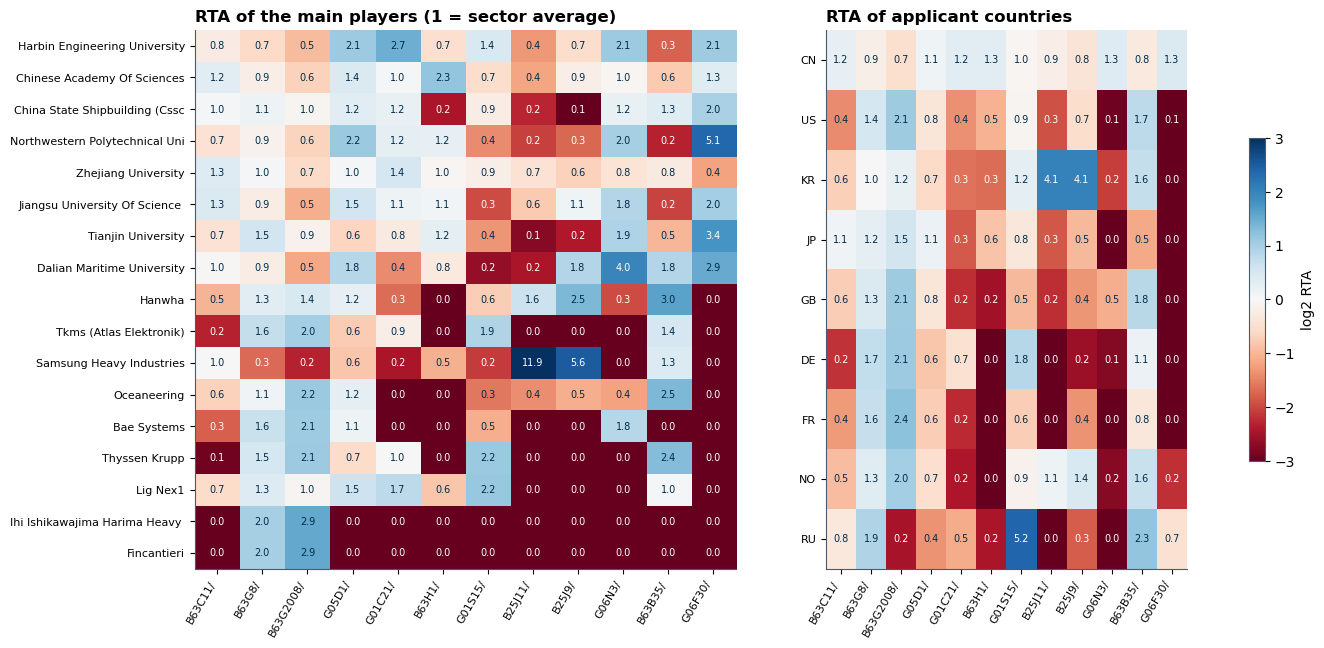

main_group,B63C11/,B63G8/,B63G2008/,G05D1/,G01C21/,B63H1/,G01S15/,B25J11/,B25J9/,G06N3/,B63B35/,G06F30/
country,,,,,,,,,,,,
CN,1.18,0.88,0.72,1.10,1.25,1.25,0.95,0.86,0.77,1.31,0.81,1.34
US,0.38,1.43,2.08,0.78,0.39,0.49,0.94,0.27,0.69,0.13,1.72,0.12
KR,0.61,1.00,1.16,0.68,0.32,0.31,1.21,4.06,4.08,0.24,1.63,0.00
JP,1.07,1.20,1.48,1.13,0.28,0.56,0.78,0.28,0.51,0.00,0.46,0.00
GB,0.60,1.35,2.11,0.77,0.22,0.17,0.51,0.22,0.40,0.47,1.77,0.00
DE,0.22,1.66,2.14,0.56,0.73,0.00,1.81,0.00,0.17,0.15,1.13,0.00
FR,0.41,1.61,2.36,0.60,0.21,0.00,0.60,0.00,0.39,0.00,0.79,0.00
NO,0.53,1.29,2.02,0.71,0.18,0.00,0.92,1.11,1.36,0.15,1.59,0.22
RU,0.81,1.87,0.18,0.39,0.46,0.18,5.20,0.00,0.28,0.00,2.26,0.73


In [34]:
key_sf = mapped.head(12).index.tolist()
mga = mg[mg.main_group.isin(key_sf)].merge(links[["docdb_family_id", "applicant", "country"]], on="docdb_family_id")
def rta_table(df, actor, actors):
    F = df.pivot_table(index=actor, columns="main_group", values="docdb_family_id", aggfunc="nunique", fill_value=0)
    rta = (F.div(F.sum(axis=1), axis=0)) / (F.sum(axis=0) / F.values.sum())
    return F.reindex(actors), rta.reindex(actors)[key_sf]

actors = list(players.index[:8]) + list(firms[firms.country != "CN"].index[:8]) + ([CLIENT] if CLIENT in players.index else [])
actors = list(dict.fromkeys(actors))
F_a, rta_a = rta_table(mga, "applicant", actors)
ctry_list = ["CN", "US", "KR", "JP", "GB", "DE", "FR", "NO", "RU"]
F_c, rta_c = rta_table(mga.drop_duplicates(["docdb_family_id", "main_group", "country"]), "country", ctry_list)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, rta, title in [(axes[0], rta_a, "RTA of the main players (1 = sector average)"), (axes[1], rta_c, "RTA of applicant countries")]:
    im = ax.imshow(np.log2(rta.astype(float).clip(lower=0.125, upper=8)), cmap="RdBu", vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(len(key_sf)), key_sf, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(rta)), [str(i) if len(str(i)) <= 3 else str(i)[:30].title() for i in rta.index], fontsize=8)
    for i in range(rta.shape[0]):
        for j in range(rta.shape[1]):
            v = rta.iat[i, j]
            if pd.notna(v): ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(np.log2(max(v, .125))) > 1.6 else NAVY)
    ax.set_title(title)
plt.colorbar(im, ax=axes, shrink=0.6, label="log2 RTA"); save(fig, "s2_rta_heatmaps"); plt.show()
rta_c.round(2)

## 2.6 Collaboration: who works with whom?

Co-applications (a family filed by two or more applicant groups) are a trace of R&D alliances, of firm–university
collaboration and of public programmes (IM_Theory_2: universities transfer knowledge through licences, spin-offs
and industry partners). The network of co-applicants among the 60 largest applicants shows the alliances; node size
= families, colour = type. Betweenness centrality identifies the *brokers* (IM_Theory_2, intermediation), which are
natural partners for an entrant such as the client.

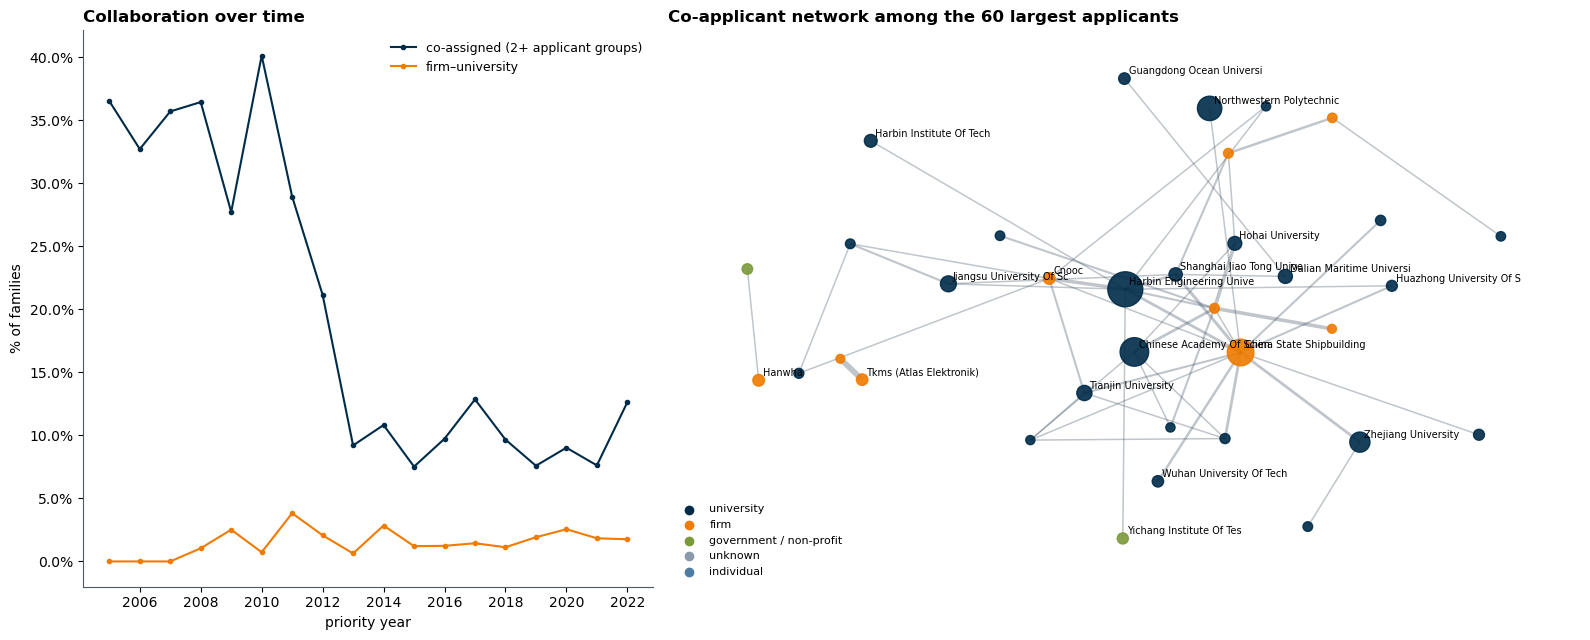

,partners (degree),betweenness,families,type
CHINA STATE SHIPBUILDING (CSSC),31,0.011,697,firm
SHANGHAI JIAO TONG UNIVERSITY,25,0.006,144,university
ZHEJIANG UNIVERSITY,29,0.005,381,university
HARBIN ENGINEERING UNIVERSITY,29,0.004,1226,university
CHINA THREE GORGES,15,0.004,60,firm
CNOOC,26,0.003,102,firm
CHINESE ACADEMY OF SCIENCES,28,0.003,804,university
CHINA HUANENG GROUP,11,0.003,57,firm
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,21,0.002,223,university
NANJING HYDRAULIC RESEARCH INSTITUTE,9,0.002,15,government / non-profit


In [35]:
co = fam[fam.family_year.between(2005, LAST)].groupby("family_year")[["co_assigned", "firm_univ_collab"]].agg(lambda s: s.astype(str).str.lower().eq("true").mean()) * 100
multi = links.groupby("docdb_family_id").filter(lambda d: len(d) > 1)
edges = (multi.merge(multi, on="docdb_family_id").query("applicant_x < applicant_y")
              .groupby(["applicant_x", "applicant_y"]).size().rename("weight").reset_index())
G = nx.Graph(); G.add_weighted_edges_from(edges.itertuples(index=False, name=None))
TOPNET = list(players.index[:60])
H = G.subgraph([n for n in TOPNET if n in G]).copy()
H.remove_nodes_from([n for n in list(H) if H.degree(n) == 0])
btw = pd.Series(nx.betweenness_centrality(G, weight=None, k=min(500, len(G)), seed=42)).sort_values(ascending=False)
deg = pd.Series(dict(G.degree())).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
co.plot(ax=axes[0], marker="o", ms=3, color=[NAVY, ORANGE]); axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); axes[0].set(title="Collaboration over time", xlabel="priority year", ylabel="% of families"); axes[0].legend(["co-assigned (2+ applicant groups)", "firm–university"], frameon=False, fontsize=9)
pos = nx.spring_layout(H, seed=3, k=0.9, weight="weight")
tcol = {"university": NAVY, "firm": ORANGE, "government / non-profit": GREEN, "unknown": MID, "individual": BLUE}
nx.draw_networkx_edges(H, pos, ax=axes[1], width=[0.4 + np.log1p(H[u][v]["weight"]) for u, v in H.edges], alpha=0.35, edge_color=GREY)
nx.draw_networkx_nodes(H, pos, ax=axes[1], node_size=[20 + players.loc[n, "families"] / 2 for n in H], node_color=[tcol.get(players.loc[n, "type"], MID) for n in H], alpha=0.9)
for n in sorted(H, key=lambda n: -players.loc[n, "families"])[:18]:
    axes[1].annotate(n.title()[:24], pos[n], fontsize=7, xytext=(3, 3), textcoords="offset points")
for t, c in tcol.items(): axes[1].scatter([], [], color=c, label=t)
axes[1].legend(frameon=False, fontsize=8, loc="lower left"); axes[1].axis("off"); axes[1].set_title("Co-applicant network among the 60 largest applicants")
plt.tight_layout(); save(fig, "s2_collaboration"); plt.show()
short(pd.DataFrame({"partners (degree)": deg, "betweenness": btw, "families": players["families"], "type": players["type"]}).dropna(subset=["partners (degree)"]).sort_values("betweenness", ascending=False).head(12)).style.format({"betweenness": "{:.3f}", "partners (degree)": "{:.0f}", "families": "{:.0f}"})

## 2.7 Where does the client stand?

Fincantieri (with WASS, Graal Tech, WSense, NextGeo, Defcomm: `GROUP_ALIASES`) against the sector: its families,
their subfields and what they look like. A tiny portfolio is itself the finding: the client has the
complementary assets (shipyards, naval programmes, customers) but not the technology portfolio, which is the
classic setting for an acquisition or a partnership (Teece, 1986): Step 6.

In [36]:
cl_ids = set(appl.loc[appl.applicant == CLIENT, "docdb_family_id"])
cl = fam[fam.docdb_family_id.isin(cl_ids)][["docdb_family_id", "family_year", "first_office", "offices", "granted_any", "fwd_cits_5y", "title_en"]]
cl_sub = mg[mg.docdb_family_id.isin(cl_ids)].groupby("main_group")["docdb_family_id"].nunique().sort_values(ascending=False)
KEY["client_families"] = int(len(cl_ids))
print(f"{CLIENT}: {len(cl_ids)} families; subfields: {cl_sub.to_dict()}")
cl.sort_values("family_year")

FINCANTIERI: 3 families; subfields: {'H01M50/': 2, 'H01M10/': 2, 'F42B19/': 2, 'H01M2220/': 2, 'B63H2021/': 1, 'B63G2008/': 1, 'B63G8/': 1, 'G01S5/': 1, 'B63H21/': 1, 'H01M2300/': 1, 'H01M6/': 1}


,docdb_family_id,family_year,first_office,offices,granted_any,fwd_cits_5y,title_en
364,40433835,2008,EP,EP,True,3,System and method for acoustic tracking an underwater ve...
1206,50513984,2014,US,EP US,True,1,Underwater vehicle provided with heat exchanger
4530,66867675,2019,IT,EP FI IT US,True,0,"VALVE SYSTEM FOR AN ELECTROCHEMICAL POWER SOURCE, IN PAR..."


**Who is strong where the client is (or wants to be)?** For the subfields of the client's families, and for the
fastest-growing large subfields, the top non-university owners: the first list of *partners or targets* to score in
Steps 3–5.

In [37]:
cl_main = [s for s in cl_sub.index if mg[mg.main_group == s].docdb_family_id.nunique() >= 15]   # client subfields large enough to read
focus = list(dict.fromkeys(cl_main + list(mapped.sort_values("growth vs sector (pp)", ascending=False).head(4).index)))
rows = []
for s in focus:
    d = mg[(mg.main_group == s) & mg.family_year.between(2013, LAST)].merge(links[["docdb_family_id", "applicant", "type", "country"]], on="docdb_family_id")
    d = d[d.type.isin(["firm", "unknown", "government / non-profit"])]
    top = d.groupby("applicant")["docdb_family_id"].nunique().sort_values(ascending=False).head(5)
    rows.append({"subfield": s, "title (verify)": MAIN_GROUP_TITLES.get(s, ""), "families 2013-2022": mg[(mg.main_group == s) & mg.family_year.between(2013, LAST)].docdb_family_id.nunique(),
                 "top non-university owners (families)": "; ".join(f"{a.title()[:28]} ({n})" for a, n in top.items())})
pd.DataFrame(rows).style.hide(axis="index")

subfield,title (verify),families 2013-2022,top non-university owners (families)
H01M50/,Battery constructional details (check),23,Fincantieri (2); Bae Systems (1); Agency For Defense Developme (1); China State Shipbuilding (Cs (1); Eelume (1)
H01M10/,Secondary batteries,28,Hanwha (2); Fincantieri (2); 7Th O 5 Research Institute O (1); Aktsionernoe Obshchestvo Tse (1); Federalnoe Gosudarstvennoe U (1)
F42B19/,Marine torpedoes,37,Hamilton Sundstrand (5); Tkms (Atlas Elektronik) (4); Hanwha (3); Boeing (2); Agency For Defense Developme (2)
H01M2220/,,17,Fincantieri (2); Hanwha (2); Bae Systems (1); Boeing (1); China State Shipbuilding (Cs (1)
B63H2021/,,42,Siemens (3); Bae Systems (1); Blue Robotics (1); Boeing (1); Aerojet Rocketdyne (1)
B63G2008/,Unmanned underwater vessels (indexing),1709,China State Shipbuilding (Cs (46); United States Of America As (37); Tkms (Atlas Elektronik) (25); Oceaneering (23); Hanwha (23)
B63G8/,"Underwater vessels, e.g. submarines",2502,China State Shipbuilding (Cs (82); United States Of America As (33); Hanwha (28); Tkms (Atlas Elektronik) (25); Hangzhou Changdong Intellige (20)
G01S5/,Position-fixing,133,China State Shipbuilding (Cs (7); Electronic Science Research (3); First Institute Of Oceanogra (2); Kawasaki Heavy Industries (2); Hunan Puli Ocean Science And (2)
B63H21/,Marine propulsion power plants,184,China State Shipbuilding (Cs (5); Suzhou Yijijie Electronic Te (4); Mitsubishi Heavy Industries (4); Suzhou Huibei Electronic Tec (3); Shenzhen Kuang Chi Spatial T (2)
G06F2119/,,55,China Ship Development And D (2); Beijing Research Institute O (1); China State Shipbuilding (Cs (1); Hunan Guotian Electronic Tec (1); Nanjing Hydraulic Research I (1)


## 2.8 PEST analysis (mandatory table)

Patent data say *who, what, where*; not *why*. The PEST table needs sources outside PATSTAT (Tutorial 1 nb 11
§5.4): identify the factors, analyse their effects, classify them as opportunities or threats, prioritise, derive
strategic actions. Below, the factors we expect, each paired with the **patent evidence from this notebook** that
supports or questions it. Every factor must be backed by a cited source before it goes in the deck (defence
budgets, NATO / EU seabed-infrastructure plans, export controls, offshore-energy investment, etc.): the bracketed
items are *to verify*, not facts.

In [38]:
ai_share = sub[sub.subclass.isin(["G06N", "G06V", "G06T", "G06F"])].groupby("family_year")["weight"].sum() / sub.groupby("family_year")["weight"].sum()
y02e = sub[sub.subclass.eq("Y02E")].groupby("family_year")["weight"].sum() / sub.groupby("family_year")["weight"].sum()
ev_signal = {"AI / vision / computing share of the CPC mix, 2013-17 → 2018-22":
             f"{ai_share.loc[PAST[0]:PAST[1]].mean():.1%} → {ai_share.loc[RECENT[0]:RECENT[1]].mean():.1%}",
             "Energy (Y02E) share, 2013-17 → 2018-22": f"{y02e.loc[PAST[0]:PAST[1]].mean():.1%} → {y02e.loc[RECENT[0]:RECENT[1]].mean():.1%}",
             "Families first filed in China": pct(KEY["share_first_filed_CN"]),
             "Share owned by universities (fractional)": pct(KEY["share_university"]),
             "US Navy / defence bodies among top owners": ", ".join([a.title()[:40] for a in players.index[:40] if re.search("NAVY|DEFEN|MILITARY|VOENN|DIRECTION GENERALE DE L ARMEMENT", a)])}
pest = pd.DataFrame([
    ("Political", "Defence and naval spending; seabed-warfare and critical-infrastructure protection programmes [source]", "opportunity", "US Navy / Russian military bodies among owners; secrecy limits patent visibility (1.5)"),
    ("Political", "Chinese industrial policy and patent subsidies [Dang & Motohashi 2015]", "threat (competition) / bias (data)", "share first filed in China; low internationalisation of CN families (1.4)"),
    ("Political", "Export controls and dual-use rules on UUVs [source]", "threat", "few cross-bloc filings in the origin × destination matrix (1.4)"),
    ("Economic", "Offshore energy (oil & gas decommissioning, offshore wind O&M) demand for inspection [source]", "opportunity", "Y02E share; offshore-wind grey zone in Step 0; TechnipFMC/Oceaneering/Saipem in the players"),
    ("Economic", "Consolidation of the market: acquisitions of UUV makers by defence primes [source: e.g. Fincantieri–WASS 2025]", "opportunity / threat", "group aliases in config; concentration trend (2.1.1)"),
    ("Social", "Safety: replacing divers in hazardous subsea work; ocean science and environmental monitoring [source]", "opportunity", "topics on monitoring / sampling (2.4.2)"),
    ("Technological", "Autonomy and AI (navigation, path planning, perception) [source]", "opportunity", "growth of G05D / G06N / G06V subfields; control titles (1.2–1.3)"),
    ("Technological", "Underwater communication and energy (docking, charging, batteries) as bottlenecks [source]", "opportunity", "H04B / H02J / docking subfields (2.4)"),
], columns=["factor", "change (to verify with a source)", "opportunity / threat", "patent evidence in this notebook"])
display(pd.Series(ev_signal, name="patent signals for the PEST").to_frame())
pest.style.hide(axis="index")

,patent signals for the PEST
"AI / vision / computing share of the CPC mix, 2013-17 → 2018-22",2.3% → 5.2%
"Energy (Y02E) share, 2013-17 → 2018-22",1.0% → 1.2%
Families first filed in China,73.1%
Share owned by universities (fractional),48.0%
US Navy / defence bodies among top owners,United States Of America As Represented


factor,change (to verify with a source),opportunity / threat,patent evidence in this notebook
Political,Defence and naval spending; seabed-warfare and critical-infrastructure protection programmes [source],opportunity,US Navy / Russian military bodies among owners; secrecy limits patent visibility (1.5)
Political,Chinese industrial policy and patent subsidies [Dang & Motohashi 2015],threat (competition) / bias (data),share first filed in China; low internationalisation of CN families (1.4)
Political,Export controls and dual-use rules on UUVs [source],threat,few cross-bloc filings in the origin × destination matrix (1.4)
Economic,"Offshore energy (oil & gas decommissioning, offshore wind O&M) demand for inspection [source]",opportunity,Y02E share; offshore-wind grey zone in Step 0; TechnipFMC/Oceaneering/Saipem in the players
Economic,Consolidation of the market: acquisitions of UUV makers by defence primes [source: e.g. Fincantieri–WASS 2025],opportunity / threat,group aliases in config; concentration trend (2.1.1)
Social,Safety: replacing divers in hazardous subsea work; ocean science and environmental monitoring [source],opportunity,topics on monitoring / sampling (2.4.2)
Technological,"Autonomy and AI (navigation, path planning, perception) [source]",opportunity,growth of G05D / G06N / G06V subfields; control titles (1.2–1.3)
Technological,"Underwater communication and energy (docking, charging, batteries) as bottlenecks [source]",opportunity,H04B / H02J / docking subfields (2.4)


## 3 · Robustness summary and exports

Every headline number on the three samples. If a conclusion holds on *all*, *without block-6-only* and
*international*, it does not depend on block 6 nor on domestic Chinese filing; if it changes, say so on the slide.

In [39]:
def headline(name, ids):
    f = fam[fam.docdb_family_id.isin(ids)]
    fc = f[f.family_year <= LAST]
    y = fc.groupby("family_year").size()
    l = links_c[links_c.docdb_family_id.isin(ids)]
    x = l.groupby("applicant")["docdb_family_id"].nunique()
    top = x.sort_values(ascending=False)
    t = l.groupby("type")["weight"].sum() / l["weight"].sum()
    return pd.Series({"families (≤2022)": len(fc), f"CAGR 2012-{LAST}": cagr(y.get(2012, np.nan), y.get(LAST, np.nan), LAST - 2012),
                      "first filed in CN": (fc.first_office == "CN").mean(), "university share": t.get("university", 0),
                      "firm share (incl. unclassified)": t.get("firm", 0) + t.get("unknown", 0),
                      "HH": herfindahl(x), "CR4": concentration_ratio(x, 4), "top applicant": top.index[0].title(),
                      "top non-CN firm": next((a.title() for a in top.index if a in firms.index and firms.loc[a, "country"] != "CN"), "–"),
                      "S-curve inflection": life.loc[name, "t0 (inflection year)"] if name in life.index else np.nan})
robust = pd.DataFrame({name: headline(name, ids) for name, ids in SAMPLES.items()}).T
robust.to_csv(OUT / "robustness_summary.csv")
robust.style.format({"families (≤2022)": "{:,.0f}", f"CAGR 2012-{LAST}": "{:.1%}", "first filed in CN": "{:.0%}", "university share": "{:.0%}",
                     "firm share (incl. unclassified)": "{:.0%}", "HH": "{:.4f}", "CR4": "{:.1%}", "S-curve inflection": "{:.1f}"})

,families (≤2022),CAGR 2012-2022,first filed in CN,university share,firm share (incl. unclassified),HH,CR4,top applicant,top non-CN firm,S-curve inflection
all,"9,991",19.9%,73%,48%,37%,0.0099,16.9%,Harbin Engineering University,Hanwha,2024.3
without block-6-only,"7,776",20.0%,72%,49%,37%,0.0106,17.3%,Harbin Engineering University,Hanwha,2023.5
international,"1,107",8.4%,17%,15%,65%,0.0034,7.2%,Tkms (Atlas Elektronik),Tkms (Atlas Elektronik),2021.1


In [40]:
for k, v in list(KEY.items()):
    KEY[k] = float(v) if isinstance(v, (np.floating, np.integer)) else v
(OUT / "key_numbers.json").write_text(json.dumps(KEY, indent=2))
for name, t in {"growth": growth, "life_cycle": life, "cpc_mix": mix, "cpc_shift": shift, "geography_owners_inventors": geo,
                "protection_profile": prot, "post_grant_events": post, "concentration": conc, "concentration_over_time": cons,
                "concentration_by_country": by_ctry, "entry_exit": ee, "rta_countries": rta_c, "rta_players": rta_a, "pest": pest}.items():
    t.to_csv(OUT / f"{name}.csv")
print(f"Saved {len(list(OUT.glob('*.csv')))} tables and {len(list(FIG.glob('*.png')))} figures in {OUT}")
pd.Series(KEY).to_frame("value")

Saved 26 tables and 15 figures in outputs/prod/step2


,value
families_total,15755.000000
families_complete_years,9991.000000
cagr_2012_last_sector,0.199015
cagr_2012_last_all_patents,0.054659
cagr_2012_last_B63,0.069911
s_curve_t0_all,2024.285322
s_curve_t0_international,2021.065425
share_first_filed_CN,0.731058
share_international,0.110800
share_university,0.480310


### Which figures go in the deck (≤ 10 figures and tables in the whole main deck)

A suggestion for Steps 1–2 (four or five slots, the rest of the deck needs the others); everything else goes in the
technical appendix.

| Slot | Figure / table | File |
|---|---|---|
| Step 1 · size and growth | families per year with truncation shaded + growth index vs all patents and B63 | `s1_volume.png`, `s1_growth_vs_benchmarks.png` (one combined panel) |
| Step 1 · technology | CPC mix over time + table of top subclasses with official titles | `s1_cpc_mix_over_time.png`, `cpc_mix.csv` |
| Step 1 · appropriability | origin & internationalisation + market leaders vs patent leaders (in the argued paragraph) | `s1_origin_internationalisation.png` |
| Step 2 · competition | top players table (firms outside China + universities) + concentration and entry over time | `players_all.csv`, `s2_concentration_over_time.png`, `s2_entry_exit.png` |
| Step 2 · subfields | growth map / maturity matrix | `s2_subfield_growth_maturity.png` |
| Step 2 · PEST | the PEST table (mandatory) | `pest.csv` |